# CredResolve — Golden Dataset and Business Analysis

## Purpose
This notebook creates working/staging copies, applies targeted deduplication and conflict checks, builds an account-level Golden Dataset, and investigates portfolio, payments, channels, targeting, and dashboard metrics.

## Grain and interpretation
- The Golden Dataset is intended to have **one row per account**; account-level fields should not multiply because of joins to event tables.
- Keep raw source data unchanged and make cleaning choices explicit.
- A repeated identifier is not sufficient evidence that two records are interchangeable. Resolve only when the available fields support the decision; otherwise flag the conflict.
- Successful-payment totals are gross recorded amounts. They are not net recovery, profit, or ROI without validated reversal matching and cost data.
- Channel and targeting comparisons are observational unless a valid experimental or counterfactual design supports causal claims.

## Scope and limitations
The monthly series should exclude August 2026 from complete-month comparisons because the supplied data ends partway through the month. The Golden Dataset and analysis outputs are deliverables for this assignment; the notebook is not yet a fully automated production pipeline with incremental loads, backfills, and monitoring.

The setup cell locates the project by finding its `dataset` folder, making paths portable across machines.

In [1]:
from pathlib import Path


def find_project_root(start: Path | None = None) -> Path:
    """Find the CredResolve project by locating its dataset/ folder.

    Works when Jupyter is launched from the project root, the notebooks folder,
    or the Desktop folder containing CredResolve.
    """
    start = (start or Path.cwd()).resolve()
    candidates = []
    for base in (start, *start.parents):
        candidates.append(base)
        candidates.append(base / "CredResolve")
    seen = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in seen:
            continue
        seen.add(candidate)
        if (candidate / "dataset").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the CredResolve project. Start Jupyter from the "
        "CredResolve folder (or its notebooks folder) and ensure that the "
        "project contains a 'dataset' folder. Current working directory: "
        f"{Path.cwd().resolve()}"
    )


PROJECT_DIR = find_project_root()
DATASET_DIR = PROJECT_DIR / "dataset"
OUTPUTS_DIR = PROJECT_DIR / "outputs"
REPORTS_DIR = PROJECT_DIR / "reports"
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_DIR)
print("Dataset folder exists:", DATASET_DIR.is_dir())
print("Outputs folder:", OUTPUTS_DIR)
print("Reports folder:", REPORTS_DIR)


Project root: C:\Users\GOPICHAND\Desktop\CredResolve
Dataset folder exists: True
Outputs folder: C:\Users\GOPICHAND\Desktop\CredResolve\outputs
Reports folder: C:\Users\GOPICHAND\Desktop\CredResolve\reports


## 1. Load source tables

Read the supplied CSVs into memory. This notebook works on copies and should not overwrite the original data.

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

In [3]:

from pathlib import Path

dataset_dir = PROJECT_DIR / "dataset"

csv_files = list(dataset_dir.glob("*.csv"))

print("Dataset folder exists:", dataset_dir.exists())
print("Number of CSV files:", len(csv_files))

print("\nFiles found:")
for file in csv_files:
    print(file.name)


Dataset folder exists: True
Number of CSV files: 18

Files found:
accounts.csv
account_status_history.csv
agents.csv
agent_sessions.csv
borrowers.csv
calls.csv
call_attempts.csv
call_dispositions.csv
campaigns.csv
complaints.csv
daily_targeting.csv
data_dictionary.csv
field_visits.csv
payments.csv
promises_to_pay.csv
sms_events.csv
vendor_telephony.csv
whatsapp_events.csv


In [4]:

raw_data = {}

for file in csv_files:
    table_name = file.stem
    raw_data[table_name] = pd.read_csv(file)

print("Datasets loaded:", len(raw_data))

print("\nDataset sizes:")
for name, df in raw_data.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")


Datasets loaded: 18

Dataset sizes:
accounts: 30,000 rows × 11 columns
account_status_history: 60,000 rows × 8 columns
agents: 30,000 rows × 8 columns
agent_sessions: 15,000 rows × 7 columns
borrowers: 30,600 rows × 8 columns
calls: 91,350 rows × 11 columns
call_attempts: 120,000 rows × 9 columns
call_dispositions: 35,000 rows × 8 columns
campaigns: 120 rows × 7 columns
complaints: 8,000 rows × 9 columns
daily_targeting: 45,000 rows × 7 columns
data_dictionary: 143 rows × 3 columns
field_visits: 25,000 rows × 10 columns
payments: 25,500 rows × 9 columns
promises_to_pay: 18,000 rows × 9 columns
sms_events: 45,000 rows × 8 columns
vendor_telephony: 15 rows × 6 columns
whatsapp_events: 60,600 rows × 8 columns


## 2. Create staging copies and inspect keys

Remove only fully identical rows at this general staging stage, then apply table-specific checks for repeated business identifiers.

In [5]:
staging_data = {}

for table_name, df in raw_data.items():
    staging_data[table_name] = df.drop_duplicates().copy()

print("Staging tables created:", len(staging_data))

print("\nDuplicate rows removed:")
for table_name in raw_data:
    removed = len(raw_data[table_name]) - len(staging_data[table_name])
    if removed > 0:
        print(f"{table_name}: {removed:,}")

Staging tables created: 18

Duplicate rows removed:
borrowers: 600
calls: 1,271
payments: 486
whatsapp_events: 600


In [6]:

primary_keys = {
    "accounts": "account_id",
    "account_status_history": "history_id",
    "agents": "agent_id",
    "agent_sessions": "session_id",
    "borrowers": "borrower_id",
    "call_attempts": "attempt_id",
    "call_dispositions": "disposition_id",
    "calls": "call_id",
    "campaigns": "campaign_id",
    "complaints": "complaint_id",
    "daily_targeting": "target_id",
    "field_visits": "visit_id",
    "payments": "payment_id",
    "promises_to_pay": "ptp_id",
    "sms_events": "sms_event_id",
    "vendor_telephony": "vendor_id",
    "whatsapp_events": "whatsapp_event_id"
}

id_quality = []

for table_name, key in primary_keys.items():
    df = staging_data[table_name]
    id_quality.append({
        "table": table_name,
        "id_column": key,
        "missing_ids": df[key].isna().sum(),
        "unique_ids": df[key].nunique(),
        "duplicate_id_rows": df[key].duplicated().sum()
    })

id_quality_df = pd.DataFrame(id_quality)
display(id_quality_df)


,table,id_column,missing_ids,unique_ids,duplicate_id_rows
0,accounts,account_id,0,30000,0
1,account_status_history,history_id,0,60000,0
2,agents,agent_id,0,1000,29000
3,agent_sessions,session_id,0,15000,0
4,borrowers,borrower_id,0,11015,18985
5,call_attempts,attempt_id,0,120000,0
6,call_dispositions,disposition_id,0,35000,0
7,calls,call_id,0,90000,79
8,campaigns,campaign_id,0,120,0
9,complaints,complaint_id,0,8000,0


## 3. Call deduplication and conflict handling

Investigate repeated call IDs and resolve only those cases supported by consistent timestamps and fields; preserve visibility into conflicts.

In [7]:

calls_df = staging_data["calls"]

duplicate_calls = calls_df[
    calls_df.duplicated(subset="call_id", keep=False)
].sort_values("call_id")

print("Rows involved in duplicate call IDs:", len(duplicate_calls))
print("Number of duplicate call IDs:", duplicate_calls["call_id"].nunique())

display(duplicate_calls.head(20))


Rows involved in duplicate call IDs: 158
Number of duplicate call IDs: 79


,call_id,account_id,borrower_id,event_at,agent_id,campaign_id,direction,vendor_id,call_status,duration_sec,timezone
225,CALL0000226,ACC0010288,BRW0011653,2026-01-09 11:36:06,AGT0000584,CMP0000108,OUTBOUND,VND0000015,VOICEMAIL,184,Asia/Dubai
90485,CALL0000226,ACC0010288,BRW0011653,2026-01-12 11:36:06,AGT0000584,CMP0000108,OUTBOUND,VND0000015,VOICEMAIL,184,Asia/Dubai
1605,CALL0001606,ACC0028730,BRW0011773,2026-02-28 06:39:17,NaN,CMP0000019,OUTBOUND,VND0000007,FAILED,845,Asia/Dubai
90739,CALL0001606,ACC0028730,BRW0011773,2026-02-28 06:39:17,AGT0000504,CMP0000019,OUTBOUND,VND0000007,FAILED,845,Asia/Dubai
1810,CALL0001811,ACC0020868,BRW0000316,2026-05-14 02:18:37,NaN,CMP0000009,OUTBOUND,VND0000015,BUSY,360,Asia/Kolkata
90953,CALL0001811,ACC0020868,BRW0000316,2026-05-14 02:18:37,AGT0000531,CMP0000009,OUTBOUND,VND0000015,BUSY,360,Asia/Kolkata
90125,CALL0003082,ACC0006316,BRW0007107,2026-04-18 14:14:49,AGT0000120,CMP0000094,OUTBOUND,VND0000003,BUSY,10,Asia/Dubai
3081,CALL0003082,ACC0006316,BRW0007107,2026-04-18 14:14:49,NaN,CMP0000094,OUTBOUND,VND0000003,BUSY,10,Asia/Dubai
91153,CALL0004229,ACC0014927,BRW0000039,2026-05-16 07:06:49,AGT0000433,CMP0000082,OUTBOUND,VND0000001,NO_ANSWER,278,UTC
4228,CALL0004229,ACC0014927,BRW0000039,2026-05-16 07:06:49,NaN,CMP0000082,OUTBOUND,VND0000001,NO_ANSWER,278,UTC


In [8]:
duplicate_columns = [
    "account_id", "borrower_id", "event_at", "agent_id",
    "campaign_id", "direction", "vendor_id",
    "call_status", "duration_sec", "timezone"
]

duplicate_analysis = []

for call_id, group in duplicate_calls.groupby("call_id"):
    differing = [
        col for col in duplicate_columns
        if group[col].nunique(dropna=False) > 1
    ]

    duplicate_analysis.append({
        "call_id": call_id,
        "rows": len(group),
        "differing_columns": ", ".join(differing)
    })

duplicate_analysis_df = pd.DataFrame(duplicate_analysis)

print("Duplicate call ID groups:", len(duplicate_analysis_df))
print("\nColumns that differ:")
display(
    duplicate_analysis_df["differing_columns"]
    .value_counts()
    .rename_axis("differing_columns")
    .reset_index(name="number_of_groups")
)

print("\nDetailed results:")
display(duplicate_analysis_df.head(15))

Duplicate call ID groups: 79

Columns that differ:


,differing_columns,number_of_groups
0,agent_id,68
1,event_at,11



Detailed results:


,call_id,rows,differing_columns
0,CALL0000226,2,event_at
1,CALL0001606,2,agent_id
2,CALL0001811,2,agent_id
3,CALL0003082,2,agent_id
4,CALL0004229,2,agent_id
5,CALL0005099,2,event_at
6,CALL0007215,2,agent_id
7,CALL0008417,2,agent_id
8,CALL0008648,2,event_at
9,CALL0012980,2,agent_id


In [9]:

calls_clean = staging_data["calls"].copy()

# Fill missing agent IDs only when the same call ID has one known agent ID
agent_counts = (
    calls_clean.groupby("call_id")["agent_id"]
    .nunique()
)

safe_ids = agent_counts[agent_counts == 1].index

calls_clean["agent_id"] = calls_clean["agent_id"].fillna(
    calls_clean["call_id"].map(
        calls_clean[calls_clean["call_id"].isin(safe_ids)]
        .groupby("call_id")["agent_id"]
        .first()
    )
)

# Remove duplicate call rows only for IDs whose timestamps do not conflict
timestamp_counts = (
    calls_clean.groupby("call_id")["event_at"]
    .nunique(dropna=False)
)

safe_duplicate_ids = timestamp_counts[
    (timestamp_counts == 1)
].index

calls_clean = pd.concat([
    calls_clean[
        ~calls_clean["call_id"].isin(
            duplicate_calls.loc[
                duplicate_calls["event_at"].duplicated(keep=False),
                "call_id"
            ]
        )
    ].drop_duplicates(subset="call_id", keep="first"),
    calls_clean[
        calls_clean["call_id"].isin(
            duplicate_analysis_df.loc[
                duplicate_analysis_df["differing_columns"] == "event_at",
                "call_id"
            ]
        )
    ]
]).sort_index()

print("Rows before:", len(staging_data["calls"]))
print("Rows after:", len(calls_clean))
print("Unique call IDs:", calls_clean["call_id"].nunique())
print("Remaining duplicate call IDs:", calls_clean["call_id"].duplicated().sum())


Rows before: 90079
Rows after: 89954
Unique call IDs: 89932
Remaining duplicate call IDs: 22


In [10]:

calls_clean = staging_data["calls"].copy()

# Identify the 11 IDs with conflicting timestamps
timestamp_conflict_ids = duplicate_analysis_df.loc[
    duplicate_analysis_df["differing_columns"] == "event_at",
    "call_id"
].tolist()

# For other duplicate IDs, fill missing agent_id and keep one row
safe_ids = [
    cid for cid in calls_clean["call_id"].unique()
    if cid not in timestamp_conflict_ids
]

safe_calls = calls_clean[calls_clean["call_id"].isin(safe_ids)].copy()

safe_calls["agent_id"] = safe_calls["agent_id"].fillna(
    safe_calls.groupby("call_id")["agent_id"].transform("first")
)

safe_calls = safe_calls.drop_duplicates(subset="call_id", keep="first")

# Preserve all records for timestamp-conflict IDs
conflict_calls = calls_clean[
    calls_clean["call_id"].isin(timestamp_conflict_ids)
].copy()

# Combine both groups
calls_clean = pd.concat(
    [safe_calls, conflict_calls],
    ignore_index=True
)

print("Rows after cleaning:", len(calls_clean))
print("Unique call IDs:", calls_clean["call_id"].nunique())
print("Remaining duplicate ID rows:", calls_clean["call_id"].duplicated().sum())
print("Timestamp-conflict IDs preserved:", len(timestamp_conflict_ids))


Rows after cleaning: 90011
Unique call IDs: 90000
Remaining duplicate ID rows: 11
Timestamp-conflict IDs preserved: 11


In [11]:
staging_data["calls"] = calls_clean.copy()

print("Calls staging table updated.")
print("Rows:", len(staging_data["calls"]))
print("Unique call IDs:", staging_data["calls"]["call_id"].nunique())


Calls staging table updated.
Rows: 90011
Unique call IDs: 90000


## 4. Payment reconciliation and duplicate handling

Inspect payment-ID versions, status agreement, and reused transaction references. Deduplication must not erase legitimate separate payments.

In [12]:
payments_before = staging_data["payments"].copy()

payment_core_columns = [
    "account_id",
    "borrower_id",
    "event_at",
    "amount",
    "payment_status",
    "payment_method",
    "provider_id"
]

# Verify that duplicate payment IDs agree on their core fields
duplicate_payment_rows = payments_before[
    payments_before.duplicated("payment_id", keep=False)
]

core_conflicts = []

for payment_id, group in duplicate_payment_rows.groupby("payment_id"):
    for col in payment_core_columns:
        if group[col].nunique(dropna=False) > 1:
            core_conflicts.append((payment_id, col))

print("Duplicate payment IDs:", duplicate_payment_rows["payment_id"].nunique())
print("Core-field conflicts:", len(core_conflicts))

if core_conflicts:
    print("Do not consolidate yet. Investigate these conflicts:", core_conflicts)
else:
    staging_data["payments"] = (
        payments_before.groupby("payment_id", as_index=False, sort=False)
        .first()
    )
    print("Payments consolidated successfully.")
    print("Rows before:", len(payments_before))
    print("Rows after:", len(staging_data["payments"]))
    print("Unique payment IDs:", staging_data["payments"]["payment_id"].nunique())


Duplicate payment IDs: 14
Core-field conflicts: 0
Payments consolidated successfully.
Rows before: 25014
Rows after: 25000
Unique payment IDs: 25000


In [13]:

staging_summary = []

for table_name, df in staging_data.items():
    key = primary_keys.get(table_name)

    staging_summary.append({
        "table": table_name,
        "rows": len(df),
        "columns": len(df.columns),
        "id_column": key if key else "N/A",
        "unique_ids": df[key].nunique() if key else None,
        "duplicate_id_rows": int(df[key].duplicated().sum()) if key else None
    })

staging_summary_df = pd.DataFrame(staging_summary)

display(staging_summary_df)


,table,rows,columns,id_column,unique_ids,duplicate_id_rows
0,accounts,30000,11,account_id,30000.0,0.0
1,account_status_history,60000,8,history_id,60000.0,0.0
2,agents,30000,8,agent_id,1000.0,29000.0
3,agent_sessions,15000,7,session_id,15000.0,0.0
4,borrowers,30000,8,borrower_id,11015.0,18985.0
5,calls,90011,11,call_id,90000.0,11.0
6,call_attempts,120000,9,attempt_id,120000.0,0.0
7,call_dispositions,35000,8,disposition_id,35000.0,0.0
8,campaigns,120,7,campaign_id,120.0,0.0
9,complaints,8000,9,complaint_id,8000.0,0.0


## 5. Build the account-level Golden Dataset

Start from the account grain and aggregate event-level activity before joining it back. This helps prevent row multiplication from one-to-many joins.

In [14]:
# Start with one row per account
golden_accounts = staging_data["accounts"].copy()

# Aggregate successful payments by account
successful_payments = staging_data["payments"].copy()
successful_payments["amount"] = pd.to_numeric(
    successful_payments["amount"], errors="coerce"
)

successful_payments = successful_payments[
    successful_payments["payment_status"].eq("SUCCESS")
]

payment_summary = (
    successful_payments
    .groupby("account_id")
    .agg(
        successful_payment_count=("payment_id", "nunique"),
        successful_payment_amount=("amount", "sum"),
        last_successful_payment_at=("event_at", "max")
    )
    .reset_index()
)

# Join the aggregated summary to accounts
golden_accounts = golden_accounts.merge(
    payment_summary,
    on="account_id",
    how="left",
    validate="one_to_one"
)

golden_accounts["successful_payment_count"] = (
    golden_accounts["successful_payment_count"].fillna(0).astype(int)
)
golden_accounts["successful_payment_amount"] = (
    golden_accounts["successful_payment_amount"].fillna(0)
)

print("Golden account rows:", len(golden_accounts))
print("Unique account IDs:", golden_accounts["account_id"].nunique())
print("Columns:", golden_accounts.columns.tolist())

display(golden_accounts.head())


Golden account rows: 30000
Unique account IDs: 30000
Columns: ['account_id', 'borrower_id', 'loan_type', 'principal_amount', 'outstanding_amount', 'dpd', 'risk_segment', 'status', 'opened_at', 'timezone', 'schema_version', 'successful_payment_count', 'successful_payment_amount', 'last_successful_payment_at']


,account_id,borrower_id,loan_type,principal_amount,outstanding_amount,dpd,risk_segment,status,opened_at,timezone,schema_version,successful_payment_count,successful_payment_amount,last_successful_payment_at
0,ACC0000001,BRW0010742,CONSUMER,603443.40,678074.03,15,MEDIUM,CLOSED,2025-11-11 04:37:00,Asia/Dubai,v1,1,114222.84,2026-04-09 17:09:27
1,ACC0000002,BRW0009382,BNPL,277190.14,464893.44,5,LOW,ACTIVE,2025-11-13 15:59:44,UTC,v3,0,0.00,NaN
2,ACC0000003,BRW0003966,CREDIT_CARD,628658.43,22565.37,60,NPA,WRITEOFF,2025-09-12 04:59:20,Asia/Dubai,v2,2,118181.69,2026-06-22 00:35:27
3,ACC0000004,BRW0001993,PERSONAL,76435.07,508427.73,30,LOW,CLOSED,2025-05-25 19:29:38,UTC,v2,1,120763.00,2026-06-24 20:53:31
4,ACC0000005,BRW0009976,CONSUMER,646797.08,563858.01,180,LOW,WRITEOFF,2025-09-07 14:59:13,Asia/Dubai,v2,0,0.00,NaN


In [15]:
quality_checks = pd.DataFrame({
    "check": [
        "Total accounts",
        "Unique account IDs",
        "Missing borrower IDs",
        "Missing outstanding amounts",
        "Negative outstanding amounts",
        "Outstanding greater than principal",
        "Closed accounts with positive outstanding",
        "Written-off accounts with positive outstanding"
    ],
    "result": [
        len(golden_accounts),
        golden_accounts["account_id"].nunique(),
        golden_accounts["borrower_id"].isna().sum(),
        golden_accounts["outstanding_amount"].isna().sum(),
        (golden_accounts["outstanding_amount"] < 0).sum(),
        (
            golden_accounts["outstanding_amount"]
            > golden_accounts["principal_amount"]
        ).sum(),
        (
            golden_accounts["status"].eq("CLOSED")
            & golden_accounts["outstanding_amount"].gt(0)
        ).sum(),
        (
            golden_accounts["status"].eq("WRITEOFF")
            & golden_accounts["outstanding_amount"].gt(0)
        ).sum()
    ]
})

display(quality_checks)


,check,result
0,Total accounts,30000
1,Unique account IDs,30000
2,Missing borrower IDs,455
3,Missing outstanding amounts,0
4,Negative outstanding amounts,0
5,Outstanding greater than principal,13029
6,Closed accounts with positive outstanding,7496
7,Written-off accounts with positive outstanding,7479


In [16]:

golden_accounts["missing_borrower_id_flag"] = (
    golden_accounts["borrower_id"].isna()
)

golden_accounts["outstanding_exceeds_principal_flag"] = (
    golden_accounts["outstanding_amount"]
    > golden_accounts["principal_amount"]
)

golden_accounts["closed_with_outstanding_flag"] = (
    golden_accounts["status"].eq("CLOSED")
    & golden_accounts["outstanding_amount"].gt(0)
)

golden_accounts["written_off_with_outstanding_flag"] = (
    golden_accounts["status"].eq("WRITEOFF")
    & golden_accounts["outstanding_amount"].gt(0)
)

print("Quality flags added.")

display(
    golden_accounts[
        [
            "account_id",
            "status",
            "principal_amount",
            "outstanding_amount",
            "missing_borrower_id_flag",
            "outstanding_exceeds_principal_flag",
            "closed_with_outstanding_flag",
            "written_off_with_outstanding_flag"
        ]
    ].head()
)


Quality flags added.


,account_id,status,principal_amount,outstanding_amount,missing_borrower_id_flag,outstanding_exceeds_principal_flag,closed_with_outstanding_flag,written_off_with_outstanding_flag
0,ACC0000001,CLOSED,603443.40,678074.03,False,True,True,False
1,ACC0000002,ACTIVE,277190.14,464893.44,False,True,False,False
2,ACC0000003,WRITEOFF,628658.43,22565.37,False,False,False,True
3,ACC0000004,CLOSED,76435.07,508427.73,False,True,True,False
4,ACC0000005,WRITEOFF,646797.08,563858.01,False,False,False,True


In [17]:

output_dir = PROJECT_DIR / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

golden_path = output_dir / "golden_accounts.csv"
golden_accounts.to_csv(golden_path, index=False)

print("Golden dataset saved successfully!")
print("Location:", golden_path)
print("Rows:", len(golden_accounts))
print("Columns:", len(golden_accounts.columns))


Golden dataset saved successfully!
Location: C:\Users\GOPICHAND\Desktop\CredResolve\outputs\golden_accounts.csv
Rows: 30000
Columns: 18


## 6. Data-quality checks and Golden Dataset export

Create explicit quality flags and export the account-level analytical table and related evidence files.

In [18]:
quality_report = pd.DataFrame([
    {
        "table": "borrowers",
        "issue": "Conflicting borrower profiles",
        "finding": "8,518 borrower IDs have multiple records",
        "action": "Preserve records; investigate identity conflicts"
    },
    {
        "table": "borrowers",
        "issue": "Timestamp inconsistency",
        "finding": "50.21% of records have updated_at earlier than created_at",
        "action": "Preserve timestamps; flag invalid ordering"
    },
    {
        "table": "agents",
        "issue": "Conflicting agent identities",
        "finding": "All 1,000 agent IDs have multiple employee codes, names, and vendors",
        "action": "Preserve records; exclude from agent-level ranking"
    },
    {
        "table": "calls",
        "issue": "Repeated call IDs with conflicting timestamps",
        "finding": "11 call IDs have different timestamps",
        "action": "Preserve both records; investigate"
    },
    {
        "table": "payments",
        "issue": "Repeated payment IDs",
        "finding": "14 repeated IDs consolidated after core-field checks",
        "action": "Retain consolidation rule and audit trail"
    },
    {
        "table": "accounts",
        "issue": "Outstanding exceeds principal",
        "finding": "13,029 accounts flagged",
        "action": "Investigate business rules; do not change values"
    },
    {
        "table": "accounts",
        "issue": "Closed or written-off accounts with outstanding balances",
        "finding": "7,496 closed and 7,479 written-off accounts flagged",
        "action": "Confirm status and balance definitions"
    },
    {
        "table": "accounts",
        "issue": "Missing borrower ID",
        "finding": "455 accounts have no borrower ID",
        "action": "Flag and investigate account mapping"
    },
    {
        "table": "whatsapp_events",
        "issue": "Exact duplicate rows",
        "finding": "600 exact duplicates removed",
        "action": "Preserve original source and cleaning rule"
    }
])

report_path = output_dir / "data_quality_report.csv"
quality_report.to_csv(report_path, index=False)

print("Data quality report saved:", report_path)
display(quality_report)


Data quality report saved: C:\Users\GOPICHAND\Desktop\CredResolve\outputs\data_quality_report.csv


,table,issue,finding,action
0,borrowers,Conflicting borrower profiles,"8,518 borrower IDs have multiple records",Preserve records; investigate identity conflicts
1,borrowers,Timestamp inconsistency,50.21% of records have updated_at earlier than...,Preserve timestamps; flag invalid ordering
2,agents,Conflicting agent identities,"All 1,000 agent IDs have multiple employee cod...",Preserve records; exclude from agent-level ran...
3,calls,Repeated call IDs with conflicting timestamps,11 call IDs have different timestamps,Preserve both records; investigate
4,payments,Repeated payment IDs,14 repeated IDs consolidated after core-field ...,Retain consolidation rule and audit trail
5,accounts,Outstanding exceeds principal,"13,029 accounts flagged",Investigate business rules; do not change values
6,accounts,Closed or written-off accounts with outstandin...,"7,496 closed and 7,479 written-off accounts fl...",Confirm status and balance definitions
7,accounts,Missing borrower ID,455 accounts have no borrower ID,Flag and investigate account mapping
8,whatsapp_events,Exact duplicate rows,600 exact duplicates removed,Preserve original source and cleaning rule


In [19]:
cleaning_rules = pd.DataFrame([
    {
        "table": "all tables",
        "rule": "Remove exact duplicate rows",
        "reason": "Avoid counting identical records more than once",
        "status": "Applied; original data preserved"
    },
    {
        "table": "calls",
        "rule": "Consolidate duplicate IDs differing only in agent_id",
        "reason": "Retain the available agent ID when the other copy is missing it",
        "status": "Applied to 68 duplicate ID groups"
    },
    {
        "table": "calls",
        "rule": "Preserve records with conflicting timestamps",
        "reason": "Avoid deleting potentially distinct events",
        "status": "11 call IDs retained for investigation"
    },
    {
        "table": "payments",
        "rule": "Consolidate duplicate IDs after core-field validation",
        "reason": "Core payment fields matched across duplicate records",
        "status": "Applied to 14 duplicate payment IDs"
    },
    {
        "table": "borrowers",
        "rule": "Do not deduplicate by borrower_id alone",
        "reason": "Multiple records have conflicting profile details",
        "status": "Preserved for identity resolution"
    },
    {
        "table": "agents",
        "rule": "Do not deduplicate by agent_id alone",
        "reason": "Agent identity attributes conflict",
        "status": "Preserved for identity resolution"
    },
    {
        "table": "accounts",
        "rule": "Flag questionable balances and statuses",
        "reason": "Business rules are not yet confirmed",
        "status": "Flags added; source values unchanged"
    }
])

rules_path = output_dir / "cleaning_rules.csv"
cleaning_rules.to_csv(rules_path, index=False)

print("Cleaning rules saved:", rules_path)
display(cleaning_rules)


Cleaning rules saved: C:\Users\GOPICHAND\Desktop\CredResolve\outputs\cleaning_rules.csv


,table,rule,reason,status
0,all tables,Remove exact duplicate rows,Avoid counting identical records more than once,Applied; original data preserved
1,calls,Consolidate duplicate IDs differing only in ag...,Retain the available agent ID when the other c...,Applied to 68 duplicate ID groups
2,calls,Preserve records with conflicting timestamps,Avoid deleting potentially distinct events,11 call IDs retained for investigation
3,payments,Consolidate duplicate IDs after core-field val...,Core payment fields matched across duplicate r...,Applied to 14 duplicate payment IDs
4,borrowers,Do not deduplicate by borrower_id alone,Multiple records have conflicting profile details,Preserved for identity resolution
5,agents,Do not deduplicate by agent_id alone,Agent identity attributes conflict,Preserved for identity resolution
6,accounts,Flag questionable balances and statuses,Business rules are not yet confirmed,Flags added; source values unchanged


In [20]:
payments = staging_data["payments"].copy()

payments["event_at"] = pd.to_datetime(
    payments["event_at"], errors="coerce"
)
payments["amount"] = pd.to_numeric(
    payments["amount"], errors="coerce"
)

successful_payments = payments[
    payments["payment_status"].eq("SUCCESS")
].copy()

successful_payments["month"] = (
    successful_payments["event_at"].dt.to_period("M")
)

monthly_recovery = (
    successful_payments.groupby("month")
    .agg(
        successful_payment_count=("payment_id", "nunique"),
        gross_successful_amount=("amount", "sum")
    )
    .reset_index()
)

monthly_recovery["mom_change_pct"] = (
    monthly_recovery["gross_successful_amount"]
    .pct_change() * 100
)

display(monthly_recovery)


,month,successful_payment_count,gross_successful_amount,mom_change_pct
0,2026-01,2464,1.872291e+08,NaN
1,2026-02,2268,1.701425e+08,-9.126077
2,2026-03,2524,1.889124e+08,11.031885
3,2026-04,2406,1.751380e+08,-7.291386
4,2026-05,2449,1.842503e+08,5.202887
5,2026-06,2366,1.755597e+08,-4.716710
6,2026-07,2441,1.872423e+08,6.654452
7,2026-08,616,4.710970e+07,-74.840245


In [21]:
monthly_recovery["month"] = monthly_recovery["month"].astype(str)

monthly_recovery["month_status"] = np.where(
    monthly_recovery["month"] == "2026-08",
    "Partial month",
    "Check completeness"
)

display(monthly_recovery)


,month,successful_payment_count,gross_successful_amount,mom_change_pct,month_status
0,2026-01,2464,1.872291e+08,NaN,Check completeness
1,2026-02,2268,1.701425e+08,-9.126077,Check completeness
2,2026-03,2524,1.889124e+08,11.031885,Check completeness
3,2026-04,2406,1.751380e+08,-7.291386,Check completeness
4,2026-05,2449,1.842503e+08,5.202887,Check completeness
5,2026-06,2366,1.755597e+08,-4.716710,Check completeness
6,2026-07,2441,1.872423e+08,6.654452,Check completeness
7,2026-08,616,4.710970e+07,-74.840245,Partial month


In [22]:
print("Earliest successful payment:",
      successful_payments["event_at"].min())

print("Latest successful payment:",
      successful_payments["event_at"].max())

print("\nSuccessful payments by month:")
display(
    successful_payments.groupby(
        successful_payments["event_at"].dt.to_period("M")
    )["event_at"]
    .agg(["min", "max", "count"])
    .reset_index()
)

Earliest successful payment: 2026-01-01 00:14:40
Latest successful payment: 2026-08-08 23:50:23

Successful payments by month:


,event_at,min,max,count
0,2026-01,2026-01-01 00:14:40,2026-01-31 23:48:25,2464
1,2026-02,2026-02-01 01:10:28,2026-02-28 23:57:08,2268
2,2026-03,2026-03-01 01:07:43,2026-03-31 23:41:43,2524
3,2026-04,2026-04-01 00:08:05,2026-04-30 23:45:47,2406
4,2026-05,2026-05-01 00:01:39,2026-05-31 23:23:05,2449
5,2026-06,2026-06-01 00:14:23,2026-06-30 23:58:18,2366
6,2026-07,2026-07-01 01:39:13,2026-07-31 23:39:36,2441
7,2026-08,2026-08-01 00:11:28,2026-08-08 23:50:23,616


In [23]:

monthly_recovery["month_status"] = np.where(
    monthly_recovery["month"] == "2026-08",
    "Partial month (data through Aug 8)",
    "Full calendar month observed"
)

display(monthly_recovery)


,month,successful_payment_count,gross_successful_amount,mom_change_pct,month_status
0,2026-01,2464,1.872291e+08,NaN,Full calendar month observed
1,2026-02,2268,1.701425e+08,-9.126077,Full calendar month observed
2,2026-03,2524,1.889124e+08,11.031885,Full calendar month observed
3,2026-04,2406,1.751380e+08,-7.291386,Full calendar month observed
4,2026-05,2449,1.842503e+08,5.202887,Full calendar month observed
5,2026-06,2366,1.755597e+08,-4.716710,Full calendar month observed
6,2026-07,2441,1.872423e+08,6.654452,Full calendar month observed
7,2026-08,616,4.710970e+07,-74.840245,Partial month (data through Aug 8)


In [24]:
full_months = monthly_recovery[
    monthly_recovery["month"].astype(str).between("2026-01", "2026-07")
].copy()

january_amount = full_months.iloc[0]["gross_successful_amount"]
july_amount = full_months.iloc[-1]["gross_successful_amount"]

overall_change_pct = (
    (july_amount - january_amount) / january_amount
) * 100

print(f"January gross successful payments: ₹{january_amount:,.2f}")
print(f"July gross successful payments: ₹{july_amount:,.2f}")
print(f"January-to-July change: {overall_change_pct:.2f}%")

January gross successful payments: ₹187,229,127.59
July gross successful payments: ₹187,242,265.08
January-to-July change: 0.01%


In [25]:
payment_status_summary = (
    staging_data["payments"]
    .groupby("payment_status")
    .agg(
        payment_count=("payment_id", "nunique"),
        total_amount=("amount", "sum")
    )
    .reset_index()
)

payment_status_summary["total_amount"] = (
    pd.to_numeric(payment_status_summary["total_amount"], errors="coerce")
)

display(payment_status_summary)

,payment_status,payment_count,total_amount
0,FAILED,3677,2.784186e+08
1,PENDING,2535,1.902232e+08
2,REVERSED,1254,9.466657e+07
3,SUCCESS,17534,1.315584e+09


In [26]:
payment_status_summary["payment_count_pct"] = (
    payment_status_summary["payment_count"]
    / payment_status_summary["payment_count"].sum()
) * 100

payment_status_summary["amount_in_crores"] = (
    payment_status_summary["total_amount"] / 10_000_000
)

display(
    payment_status_summary[
        [
            "payment_status",
            "payment_count",
            "payment_count_pct",
            "amount_in_crores"
        ]
    ].round(2)
)

,payment_status,payment_count,payment_count_pct,amount_in_crores
0,FAILED,3677,14.71,27.84
1,PENDING,2535,10.14,19.02
2,REVERSED,1254,5.02,9.47
3,SUCCESS,17534,70.14,131.56


In [27]:
payments_check = staging_data["payments"].copy()

print("Total payment records:", len(payments_check))
print(
    "Missing payment references:",
    payments_check["payment_reference"].isna().sum()
)
print(
    "Unique non-missing references:",
    payments_check["payment_reference"].nunique()
)

reference_counts = (
    payments_check.dropna(subset=["payment_reference"])
    .groupby("payment_reference")["payment_id"]
    .nunique()
)

print(
    "References linked to multiple payment IDs:",
    (reference_counts > 1).sum()
)

Total payment records: 25000
Missing payment references: 368
Unique non-missing references: 20821
References linked to multiple payment IDs: 3407


In [28]:
reference_status_check = (
    staging_data["payments"]
    .dropna(subset=["payment_reference"])
    .groupby("payment_reference")
    .agg(
        payment_ids=("payment_id", "nunique"),
        statuses=("payment_status", "nunique"),
        status_list=("payment_status", lambda x: ", ".join(sorted(x.unique())))
    )
    .reset_index()
)

reused_references = reference_status_check[
    reference_status_check["payment_ids"] > 1
]

print("Reused references:", len(reused_references))
print(
    "Reused references spanning multiple statuses:",
    (reused_references["statuses"] > 1).sum()
)

display(reused_references.head(10))

Reused references: 3407
Reused references spanning multiple statuses: 1681


,payment_reference,payment_ids,statuses,status_list
5,TXN0000000027,2,2,"FAILED, SUCCESS"
8,TXN0000000032,3,2,"PENDING, SUCCESS"
28,TXN0000000113,3,2,"REVERSED, SUCCESS"
35,TXN0000000132,2,1,SUCCESS
36,TXN0000000134,2,1,FAILED
39,TXN0000000154,2,1,SUCCESS
50,TXN0000000186,2,1,SUCCESS
53,TXN0000000196,2,1,SUCCESS
58,TXN0000000212,2,1,SUCCESS
71,TXN0000000271,2,1,SUCCESS


In [29]:
payments_check = staging_data["payments"].copy()

payments_check["amount"] = pd.to_numeric(
    payments_check["amount"], errors="coerce"
)

successful = payments_check[
    payments_check["payment_status"] == "SUCCESS"
]

reversed = payments_check[
    payments_check["payment_status"] == "REVERSED"
]

match_columns = ["account_id", "amount"]

success_keys = successful[match_columns].drop_duplicates()
reversed_keys = reversed[match_columns].drop_duplicates()

possible_matches = success_keys.merge(
    reversed_keys,
    on=match_columns,
    how="inner"
)

print("Successful payment records:", len(successful))
print("Reversed payment records:", len(reversed))
print(
    "Account-and-amount combinations present in both statuses:",
    len(possible_matches)
)

display(possible_matches.head(10))

Successful payment records: 17534
Reversed payment records: 1254
Account-and-amount combinations present in both statuses: 0


,account_id,amount


In [30]:
new_issue = pd.DataFrame([{
    "table": "payments",
    "issue": "Reversal reconciliation",
    "finding": (
        "1,254 reversed payment records; 3,407 reused payment references; "
        "zero exact account-and-amount combinations shared between SUCCESS "
        "and REVERSED records."
    ),
    "recommended_action": (
        "Obtain a reliable original-transaction ID and reversal linkage. "
        "Do not estimate net recovery by subtracting all reversed amounts."
    )
}])

display(new_issue)

,table,issue,finding,recommended_action
0,payments,Reversal reconciliation,"1,254 reversed payment records; 3,407 reused p...",Obtain a reliable original-transaction ID and ...


In [31]:
quality_report_path = output_dir / "data_quality_report.csv"

quality_report = pd.read_csv(quality_report_path)

print("Existing report columns:")
print(quality_report.columns.tolist())

display(quality_report.head())

Existing report columns:
['table', 'issue', 'finding', 'action']


,table,issue,finding,action
0,borrowers,Conflicting borrower profiles,"8,518 borrower IDs have multiple records",Preserve records; investigate identity conflicts
1,borrowers,Timestamp inconsistency,50.21% of records have updated_at earlier than...,Preserve timestamps; flag invalid ordering
2,agents,Conflicting agent identities,"All 1,000 agent IDs have multiple employee cod...",Preserve records; exclude from agent-level ran...
3,calls,Repeated call IDs with conflicting timestamps,11 call IDs have different timestamps,Preserve both records; investigate
4,payments,Repeated payment IDs,14 repeated IDs consolidated after core-field ...,Retain consolidation rule and audit trail


In [32]:
new_issue = pd.DataFrame([{
    "table": "payments",
    "issue": "Reversal reconciliation",
    "finding": (
        "1,254 reversed payment records; 3,407 reused payment references; "
        "zero exact account-and-amount combinations shared between SUCCESS "
        "and REVERSED records."
    ),
    "action": (
        "Obtain a reliable original-transaction ID and reversal linkage. "
        "Do not estimate net recovery by subtracting all reversed amounts."
    )
}])

quality_report = pd.concat(
    [quality_report, new_issue],
    ignore_index=True
)

quality_report.to_csv(quality_report_path, index=False)

print("Updated report saved to:", quality_report_path)
print("Total reported issues:", len(quality_report))

display(quality_report.tail(3))

Updated report saved to: C:\Users\GOPICHAND\Desktop\CredResolve\outputs\data_quality_report.csv
Total reported issues: 10


,table,issue,finding,action
7,accounts,Missing borrower ID,455 accounts have no borrower ID,Flag and investigate account mapping
8,whatsapp_events,Exact duplicate rows,600 exact duplicates removed,Preserve original source and cleaning rule
9,payments,Reversal reconciliation,"1,254 reversed payment records; 3,407 reused p...",Obtain a reliable original-transaction ID and ...


In [33]:
print("Total accounts:", len(golden_accounts))

print(
    "Accounts with at least one successful payment:",
    (golden_accounts["successful_payment_count"] > 0).sum()
)

print(
    "Accounts without successful payments:",
    (golden_accounts["successful_payment_count"] == 0).sum()
)

print(
    "Total gross successful payment amount: ₹",
    f"{golden_accounts['successful_payment_amount'].sum():,.2f}"
)

Total accounts: 30000
Accounts with at least one successful payment: 13284
Accounts without successful payments: 16716
Total gross successful payment amount: ₹ 1,315,583,964.64


In [34]:
risk_summary = (
    golden_accounts.groupby("risk_segment")
    .agg(
        total_accounts=("account_id", "nunique"),
        accounts_with_payments=(
            "successful_payment_count",
            lambda x: (x > 0).sum()
        ),
        gross_successful_amount=("successful_payment_amount", "sum"),
        total_outstanding=("outstanding_amount", "sum")
    )
    .reset_index()
)

risk_summary["account_payment_rate_pct"] = (
    risk_summary["accounts_with_payments"]
    / risk_summary["total_accounts"]
) * 100

risk_summary["gross_successful_amount_crore"] = (
    risk_summary["gross_successful_amount"] / 10_000_000
)

display(risk_summary.round(2))

,risk_segment,total_accounts,accounts_with_payments,gross_successful_amount,total_outstanding,account_payment_rate_pct,gross_successful_amount_crore
0,HIGH,7552,3300,3.315982e+08,2.646183e+09,43.70,33.16
1,LOW,7513,3381,3.308578e+08,2.633311e+09,45.00,33.09
2,MEDIUM,7533,3335,3.305101e+08,2.628179e+09,44.27,33.05
3,NPA,7402,3268,3.226178e+08,2.581362e+09,44.15,32.26


In [35]:
risk_summary["gross_payment_to_outstanding_pct"] = (
    risk_summary["gross_successful_amount"]
    / risk_summary["total_outstanding"]
) * 100

display(
    risk_summary[
        [
            "risk_segment",
            "total_accounts",
            "account_payment_rate_pct",
            "gross_successful_amount_crore",
            "gross_payment_to_outstanding_pct"
        ]
    ].round(2)
)

,risk_segment,total_accounts,account_payment_rate_pct,gross_successful_amount_crore,gross_payment_to_outstanding_pct
0,HIGH,7552,43.70,33.16,12.53
1,LOW,7513,45.00,33.09,12.56
2,MEDIUM,7533,44.27,33.05,12.58
3,NPA,7402,44.15,32.26,12.50


In [36]:
golden_accounts["dpd_bucket"] = pd.cut(
    golden_accounts["dpd"],
    bins=[-1, 0, 30, 60, 90, 180],
    labels=["0 days", "1–30 days", "31–60 days", "61–90 days", "91–180 days"]
)

dpd_summary = (
    golden_accounts.groupby("dpd_bucket", observed=False)
    .agg(
        total_accounts=("account_id", "nunique"),
        accounts_with_payments=(
            "successful_payment_count",
            lambda x: (x > 0).sum()
        ),
        gross_successful_amount=("successful_payment_amount", "sum")
    )
    .reset_index()
)

dpd_summary["account_payment_rate_pct"] = (
    dpd_summary["accounts_with_payments"]
    / dpd_summary["total_accounts"]
) * 100

dpd_summary["gross_successful_amount_crore"] = (
    dpd_summary["gross_successful_amount"] / 10_000_000
)

display(dpd_summary.round(2))

,dpd_bucket,total_accounts,accounts_with_payments,gross_successful_amount,account_payment_rate_pct,gross_successful_amount_crore
0,0 days,2685,1220,1.174619e+08,45.44,11.75
1,1–30 days,10880,4719,4.715398e+08,43.37,47.15
2,31–60 days,5514,2524,2.527771e+08,45.77,25.28
3,61–90 days,5468,2436,2.387357e+08,44.55,23.87
4,91–180 days,5453,2385,2.350695e+08,43.74,23.51


In [37]:
calls_df = staging_data["calls"].copy()

print("Available call columns:")
print(calls_df.columns.tolist())

Available call columns:
['call_id', 'account_id', 'borrower_id', 'event_at', 'agent_id', 'campaign_id', 'direction', 'vendor_id', 'call_status', 'duration_sec', 'timezone']


In [38]:
print("Campaign columns:")
print(staging_data["campaigns"].columns.tolist())

display(staging_data["campaigns"].head())

Campaign columns:
['campaign_id', 'campaign_name', 'channel', 'strategy_version', 'start_at', 'target_definition', 'end_at']


,campaign_id,campaign_name,channel,strategy_version,start_at,target_definition,end_at
0,CMP0000001,DIGITAL_FOLLOWUP,FIELD,legacy,2026-02-17 06:56:01,DPD>=30,2026-04-24 06:56:01
1,CMP0000002,BOUNCE,MIXED,v2,2026-04-30 17:51:31,DPD>=60,2026-05-18 17:51:31
2,CMP0000003,30DPD_W1,MIXED,v1,2026-04-11 16:02:51,DPD>=30,2026-05-18 16:02:51
3,CMP0000004,BOUNCE,VOICE,legacy,2026-04-28 06:15:30,DPD>=60,2026-05-29 06:15:30
4,CMP0000005,60DPD_INTENT,WHATSAPP,legacy,2026-05-04 04:16:21,DPD>=60,2026-07-08 04:16:21


In [39]:
campaigns_df = staging_data["campaigns"].copy()

calls_with_channel = calls_df.merge(
    campaigns_df[["campaign_id", "channel"]],
    on="campaign_id",
    how="left",
    validate="many_to_one"
)

print("Total call records:", len(calls_with_channel))
print("Missing campaign channels:", calls_with_channel["channel"].isna().sum())

display(calls_with_channel[["call_id", "campaign_id", "channel", "call_status"]].head())

Total call records: 90011
Missing campaign channels: 0


,call_id,campaign_id,channel,call_status
0,CALL0000001,CMP0000015,FIELD,NO_ANSWER
1,CALL0000002,CMP0000060,SMS,ANSWERED
2,CALL0000003,CMP0000060,SMS,FAILED
3,CALL0000004,CMP0000060,SMS,VOICEMAIL
4,CALL0000005,CMP0000053,VOICE,ANSWERED


In [40]:
channel_summary = (
    calls_with_channel.groupby("channel")
    .agg(
        total_call_records=("call_id", "size"),
        unique_call_ids=("call_id", "nunique"),
        answered_calls=(
            "call_status",
            lambda x: (x == "ANSWERED").sum()
        ),
        total_duration_sec=("duration_sec", "sum")
    )
    .reset_index()
)

channel_summary["answer_rate_pct"] = (
    channel_summary["answered_calls"]
    / channel_summary["total_call_records"]
) * 100

display(channel_summary.round(2))

,channel,total_call_records,unique_call_ids,answered_calls,total_duration_sec,answer_rate_pct
0,FIELD,13424,13423,2660,6036471,19.82
1,MIXED,17084,17082,3446,7735669,20.17
2,SMS,21065,21062,4176,9487799,19.82
3,VOICE,15032,15029,2904,6781675,19.32
4,WHATSAPP,23406,23404,4695,10556541,20.06


## 7. Interaction timelines and payment attribution

Compare the order of calls and successful payments with the available identifiers. Timing alone is not proof that an interaction caused a payment.

In [41]:
answered_account_ids = set(
    calls_with_channel.loc[
        calls_with_channel["call_status"].eq("ANSWERED"),
        "account_id"
    ].dropna()
)

paid_account_ids = set(
    golden_accounts.loc[
        golden_accounts["successful_payment_count"] > 0,
        "account_id"
    ]
)

overlap_accounts = answered_account_ids & paid_account_ids

print("Accounts with answered calls:", len(answered_account_ids))
print("Accounts with successful payments:", len(paid_account_ids))
print("Accounts in both groups:", len(overlap_accounts))

if answered_account_ids:
    print(
        "Answered-call accounts that also have successful payments:",
        f"{len(overlap_accounts) / len(answered_account_ids) * 100:.2f}%"
    )

Accounts with answered calls: 13535
Accounts with successful payments: 13284
Accounts in both groups: 6050
Answered-call accounts that also have successful payments: 44.70%


In [42]:
calls_df = staging_data["calls"].copy()
payments_df = staging_data["payments"].copy()

calls_df["event_at"] = pd.to_datetime(
    calls_df["event_at"], errors="coerce", utc=True
)
payments_df["event_at"] = pd.to_datetime(
    payments_df["event_at"], errors="coerce", utc=True
)

answered_calls = calls_df[
    calls_df["call_status"].eq("ANSWERED")
].copy()

successful_payments = payments_df[
    payments_df["payment_status"].eq("SUCCESS")
].copy()

# First answered call per account
first_answered_call = (
    answered_calls.dropna(subset=["account_id", "event_at"])
    .groupby("account_id")["event_at"]
    .min()
)

# First successful payment per account
first_successful_payment = (
    successful_payments.dropna(subset=["account_id", "event_at"])
    .groupby("account_id")["event_at"]
    .min()
)

timeline = pd.concat(
    [
        first_answered_call.rename("first_answered_call"),
        first_successful_payment.rename("first_successful_payment")
    ],
    axis=1
)

timeline["payment_after_call"] = (
    timeline["first_successful_payment"]
    > timeline["first_answered_call"]
)

timeline["payment_before_or_at_call"] = (
    timeline["first_successful_payment"]
    <= timeline["first_answered_call"]
)

print("Accounts with both an answered call and a successful payment:",
      timeline.dropna(subset=[
          "first_answered_call", "first_successful_payment"
      ]).shape[0])

print("\nPayment timing relative to first answered call:")
print(
    timeline.dropna(subset=[
        "first_answered_call", "first_successful_payment"
    ])[["payment_after_call", "payment_before_or_at_call"]]
    .sum()
)

Accounts with both an answered call and a successful payment: 6050

Payment timing relative to first answered call:
payment_after_call           3053
payment_before_or_at_call    2997
dtype: int64


In [43]:
payment_after_call = timeline[
    timeline["payment_after_call"].eq(True)
].copy()

payment_after_call["days_to_payment"] = (
    payment_after_call["first_successful_payment"]
    - payment_after_call["first_answered_call"]
).dt.total_seconds() / 86400

print("Accounts with payment after first answered call:",
      len(payment_after_call))

print("\nDays between first answered call and first successful payment:")
display(
    payment_after_call["days_to_payment"]
    .describe()
    .round(2)
)

Accounts with payment after first answered call: 3053

Days between first answered call and first successful payment:


count    3053.00
mean       73.47
std        53.12
min         0.03
25%        28.50
50%        62.43
75%       110.93
max       216.21
Name: days_to_payment, dtype: float64

In [44]:
delay_summary = pd.DataFrame({
    "period": [
        "Within 7 days",
        "Within 30 days",
        "Within 60 days",
        "Within 90 days"
    ],
    "accounts": [
        (payment_after_call["days_to_payment"] <= 7).sum(),
        (payment_after_call["days_to_payment"] <= 30).sum(),
        (payment_after_call["days_to_payment"] <= 60).sum(),
        (payment_after_call["days_to_payment"] <= 90).sum()
    ]
})

delay_summary["percentage_of_post_call_payers"] = (
    delay_summary["accounts"] / len(payment_after_call) * 100
)

display(delay_summary.round(2))

,period,accounts,percentage_of_post_call_payers
0,Within 7 days,197,6.45
1,Within 30 days,807,26.43
2,Within 60 days,1482,48.54
3,Within 90 days,1979,64.82


## 8. Payment and session quality checks

Check amount/status validity and session-level anomalies before interpreting operational productivity.

In [45]:
calls_check = staging_data["calls"].copy()

calls_check["event_at"] = pd.to_datetime(
    calls_check["event_at"], errors="coerce", utc=True
)

print("Total call records:", len(calls_check))
print("Missing or invalid timestamps:", calls_check["event_at"].isna().sum())
print("Missing account IDs:", calls_check["account_id"].isna().sum())
print("Missing call statuses:", calls_check["call_status"].isna().sum())

print("\nCall status distribution:")
display(calls_check["call_status"].value_counts(dropna=False).to_frame("count"))

Total call records: 90011
Missing or invalid timestamps: 0
Missing account IDs: 0
Missing call statuses: 0

Call status distribution:


,count
call_status,
NO_ANSWER,18083
BUSY,18064
FAILED,18000
VOICEMAIL,17983
ANSWERED,17881


In [46]:
payments_check = staging_data["payments"].copy()

print("Payment methods:")
display(
    payments_check["payment_method"]
    .value_counts(dropna=False)
    .to_frame("payment_records")
)

print("\nPayment providers:")
display(
    payments_check["provider_id"]
    .value_counts(dropna=False)
    .to_frame("payment_records")
)

Payment methods:


,payment_records
payment_method,
CARD,5121
NACH,5061
UPI,4965
NETBANKING,4960
CASH,4893



Payment providers:


,payment_records
provider_id,
VND0000007,1735
VND0000012,1705
VND0000008,1704
VND0000004,1700
VND0000002,1696
VND0000011,1689
VND0000001,1683
VND0000006,1669
VND0000014,1660


In [47]:
payments_check["amount"] = pd.to_numeric(
    payments_check["amount"], errors="coerce"
)

method_summary = (
    payments_check.groupby("payment_method")
    .agg(
        total_records=("payment_id", "nunique"),
        successful_records=(
            "payment_status",
            lambda x: (x == "SUCCESS").sum()
        ),
        total_amount=("amount", "sum")
    )
    .reset_index()
)

method_summary["success_rate_pct"] = (
    method_summary["successful_records"]
    / method_summary["total_records"] * 100
)

display(method_summary.round(2))

,payment_method,total_records,successful_records,total_amount,success_rate_pct
0,CARD,5121,3560,3.816730e+08,69.52
1,CASH,4893,3434,3.668127e+08,70.18
2,NACH,5061,3600,3.821342e+08,71.13
3,NETBANKING,4960,3527,3.750991e+08,71.11
4,UPI,4965,3413,3.731733e+08,68.74


In [48]:
successful_by_method = payments_check[
    payments_check["payment_status"].eq("SUCCESS")
].copy()

method_amount_summary = (
    successful_by_method.groupby("payment_method")
    .agg(
        successful_payment_count=("payment_id", "nunique"),
        total_successful_amount=("amount", "sum"),
        average_successful_payment=("amount", "mean"),
        median_successful_payment=("amount", "median")
    )
    .reset_index()
)

display(method_amount_summary.round(2))

,payment_method,successful_payment_count,total_successful_amount,average_successful_payment,median_successful_payment
0,CARD,3560,2.646148e+08,74329.99,73848.04
1,CASH,3434,2.558601e+08,74507.91,73451.12
2,NACH,3600,2.712127e+08,75336.87,75886.86
3,NETBANKING,3527,2.662853e+08,75499.10,75121.72
4,UPI,3413,2.576110e+08,75479.34,76373.90


In [49]:
method_status_summary = pd.crosstab(
    payments_check["payment_method"],
    payments_check["payment_status"]
)

display(method_status_summary)

payment_status,FAILED,PENDING,REVERSED,SUCCESS
payment_method,,,,
CARD,758,545,258,3560
CASH,712,511,236,3434
NACH,726,490,245,3600
NETBANKING,722,458,253,3527
UPI,759,531,262,3413


In [50]:
method_status_rates = pd.crosstab(
    payments_check["payment_method"],
    payments_check["payment_status"],
    normalize="index"
) * 100

method_status_rates.columns = [
    f"{col.lower()}_pct" for col in method_status_rates.columns
]

display(method_status_rates.round(2))

,failed_pct,pending_pct,reversed_pct,success_pct
payment_method,,,,
CARD,14.80,10.64,5.04,69.52
CASH,14.55,10.44,4.82,70.18
NACH,14.34,9.68,4.84,71.13
NETBANKING,14.56,9.23,5.10,71.11
UPI,15.29,10.69,5.28,68.74


In [51]:
cost_keywords = [
    "cost", "salary", "expense", "fee", "commission",
    "budget", "spend", "incentive", "amount"
]

for table_name, df in staging_data.items():
    matches = [
        col for col in df.columns
        if any(keyword in col.lower() for keyword in cost_keywords)
    ]

    if matches:
        print(f"{table_name}: {matches}")

accounts: ['principal_amount', 'outstanding_amount']
payments: ['amount']
promises_to_pay: ['promised_amount']


In [52]:
vendor_df = staging_data["vendor_telephony"].copy()

print("Vendor table columns:")
print(vendor_df.columns.tolist())

print("\nVendor table sample:")
display(vendor_df.head(10))

Vendor table columns:
['vendor_id', 'vendor_name', 'vendor_account_id', 'timezone', 'status', 'schema_version']

Vendor table sample:


,vendor_id,vendor_name,vendor_account_id,timezone,status,schema_version
0,VND0000001,Airtel,VAC342762,Asia/Kolkata,INACTIVE,v3
1,VND0000002,Exotel,VAC456766,UTC,INACTIVE,v3
2,VND0000003,Twilio,VAC074211,UTC,INACTIVE,v3
3,VND0000004,Twilio,VAC321507,UTC,ACTIVE,v1
4,VND0000005,Twilio,VAC976733,Asia/Kolkata,ACTIVE,v1
5,VND0000006,Knowlarity,VAC544470,UTC,ACTIVE,v2
6,VND0000007,TataTele,VAC997592,UTC,INACTIVE,v1
7,VND0000008,Airtel,VAC496672,Asia/Kolkata,INACTIVE,v3
8,VND0000009,Exotel,VAC382568,Asia/Kolkata,INACTIVE,v1
9,VND0000010,Airtel,VAC172916,UTC,INACTIVE,v1


In [53]:
provider_summary = (
    payments_check.groupby("provider_id")
    .agg(
        total_payments=("payment_id", "nunique"),
        successful_payments=(
            "payment_status",
            lambda x: (x == "SUCCESS").sum()
        ),
        total_amount=("amount", "sum")
    )
    .reset_index()
)

provider_summary["success_rate_pct"] = (
    provider_summary["successful_payments"]
    / provider_summary["total_payments"] * 100
)

display(
    provider_summary.sort_values(
        "success_rate_pct", ascending=False
    ).round(2)
)

,provider_id,total_payments,successful_payments,total_amount,success_rate_pct
1,VND0000002,1696,1227,1.282313e+08,72.35
5,VND0000006,1669,1200,1.256087e+08,71.90
8,VND0000009,1651,1177,1.246417e+08,71.29
14,VND0000015,1614,1149,1.214987e+08,71.19
9,VND0000010,1604,1138,1.169759e+08,70.95
7,VND0000008,1704,1204,1.314630e+08,70.66
10,VND0000011,1689,1190,1.289683e+08,70.46
3,VND0000004,1700,1194,1.303066e+08,70.24
0,VND0000001,1683,1178,1.274258e+08,69.99
11,VND0000012,1705,1193,1.272948e+08,69.97


In [54]:
provider_method_mix = pd.crosstab(
    payments_check["provider_id"],
    payments_check["payment_method"]
)

display(provider_method_mix)

payment_method,CARD,CASH,NACH,NETBANKING,UPI
provider_id,,,,,
VND0000001,345,349,329,323,337
VND0000002,331,362,362,338,303
VND0000003,329,331,320,358,320
VND0000004,354,309,370,322,345
VND0000005,324,309,317,309,332
VND0000006,340,324,317,345,343
VND0000007,355,355,366,329,330
VND0000008,378,310,338,339,339
VND0000009,350,336,317,330,318


In [55]:
provider_method_success = (
    payments_check.groupby(["provider_id", "payment_method"])
    .agg(
        total_records=("payment_id", "nunique"),
        successful_records=(
            "payment_status",
            lambda x: (x == "SUCCESS").sum()
        )
    )
    .reset_index()
)

provider_method_success["success_rate_pct"] = (
    provider_method_success["successful_records"]
    / provider_method_success["total_records"] * 100
)

provider_method_pivot = provider_method_success.pivot(
    index="provider_id",
    columns="payment_method",
    values="success_rate_pct"
)

display(provider_method_pivot.round(2))

payment_method,CARD,CASH,NACH,NETBANKING,UPI
provider_id,,,,,
VND0000001,68.70,69.91,71.73,68.42,71.22
VND0000002,76.74,74.86,70.44,69.82,69.64
VND0000003,66.87,69.18,70.00,69.55,67.81
VND0000004,70.90,69.58,68.38,73.29,69.28
VND0000005,66.98,71.84,71.29,70.87,67.77
VND0000006,73.82,69.14,75.39,72.17,69.10
VND0000007,66.20,70.70,74.59,69.60,68.18
VND0000008,70.63,71.29,73.37,70.21,67.85
VND0000009,71.71,67.26,74.45,73.94,69.18


In [56]:
vendor_lookup = staging_data["vendor_telephony"][
    ["vendor_id", "vendor_name", "status"]
].copy()

provider_named = provider_summary.merge(
    vendor_lookup,
    left_on="provider_id",
    right_on="vendor_id",
    how="left",
    validate="one_to_one"
)

display(
    provider_named[
        [
            "provider_id",
            "vendor_name",
            "status",
            "total_payments",
            "success_rate_pct"
        ]
    ].sort_values("success_rate_pct", ascending=False).round(2)
)

,provider_id,vendor_name,status,total_payments,success_rate_pct
1,VND0000002,Exotel,INACTIVE,1696,72.35
5,VND0000006,Knowlarity,ACTIVE,1669,71.90
8,VND0000009,Exotel,INACTIVE,1651,71.29
14,VND0000015,TataTele,ACTIVE,1614,71.19
9,VND0000010,Airtel,INACTIVE,1604,70.95
7,VND0000008,Airtel,INACTIVE,1704,70.66
10,VND0000011,Airtel,ACTIVE,1689,70.46
3,VND0000004,Twilio,ACTIVE,1700,70.24
0,VND0000001,Airtel,INACTIVE,1683,69.99
11,VND0000012,Airtel,INACTIVE,1705,69.97


In [57]:
payment_provider_ids = set(
    payments_check["provider_id"].dropna().unique()
)

vendor_ids = set(
    staging_data["vendor_telephony"]["vendor_id"].dropna().unique()
)

print("Unique payment provider IDs:", len(payment_provider_ids))
print("Unique telephony vendor IDs:", len(vendor_ids))
print("IDs appearing in both tables:", len(payment_provider_ids & vendor_ids))
print("Payment provider IDs without vendor matches:",
      sorted(payment_provider_ids - vendor_ids))
print("Vendor IDs without payment provider matches:",
      sorted(vendor_ids - payment_provider_ids))

Unique payment provider IDs: 15
Unique telephony vendor IDs: 15
IDs appearing in both tables: 15
Payment provider IDs without vendor matches: []
Vendor IDs without payment provider matches: []


In [58]:
provider_status_summary = (
    provider_named.groupby("status")
    .agg(
        providers=("provider_id", "nunique"),
        total_payments=("total_payments", "sum"),
        average_success_rate=("success_rate_pct", "mean")
    )
    .reset_index()
)

display(provider_status_summary.round(2))

,status,providers,total_payments,average_success_rate
0,ACTIVE,6,9904,69.97
1,INACTIVE,9,15096,70.24


In [59]:
baseline_success_amount = successful_payments["amount"].sum()

scenario = pd.DataFrame({
    "metric": [
        "Historical gross successful payment amount",
        "Illustrative 1% relative increase",
        "Illustrative 5% relative increase",
        "Illustrative 10% relative increase"
    ],
    "amount_inr": [
        baseline_success_amount,
        baseline_success_amount * 0.01,
        baseline_success_amount * 0.05,
        baseline_success_amount * 0.10
    ]
})

scenario["amount_crore"] = scenario["amount_inr"] / 10_000_000

display(scenario.round(2))

,metric,amount_inr,amount_crore
0,Historical gross successful payment amount,1.315584e+09,131.56
1,Illustrative 1% relative increase,1.315584e+07,1.32
2,Illustrative 5% relative increase,6.577920e+07,6.58
3,Illustrative 10% relative increase,1.315584e+08,13.16


In [60]:
investment_crore = 10

required_increase_pct = (
    investment_crore * 10_000_000
    / baseline_success_amount
) * 100

print(f"Investment amount: ₹{investment_crore:.2f} crore")
print(
    "Required increase in historical gross successful payments "
    f"to equal the investment: {required_increase_pct:.2f}%"
)

Investment amount: ₹10.00 crore
Required increase in historical gross successful payments to equal the investment: 7.60%


In [61]:
investment_inr = 10 * 10_000_000

scenario["gross_increase_pct"] = [0, 1, 5, 10]
scenario["investment_inr"] = investment_inr
scenario["difference_vs_investment_inr"] = (
    scenario["amount_inr"] - investment_inr
)

display(
    scenario[
        [
            "metric",
            "gross_increase_pct",
            "amount_crore",
            "difference_vs_investment_inr"
        ]
    ].round(2)
)

,metric,gross_increase_pct,amount_crore,difference_vs_investment_inr
0,Historical gross successful payment amount,0,131.56,1.215584e+09
1,Illustrative 1% relative increase,1,1.32,-8.684416e+07
2,Illustrative 5% relative increase,5,6.58,-3.422080e+07
3,Illustrative 10% relative increase,10,13.16,3.155840e+07


In [62]:
investment_inr = 10 * 10_000_000

scenario_clean = pd.DataFrame({
    "scenario": [
        "Historical baseline (not an increase)",
        "Illustrative 1% increase",
        "Illustrative 5% increase",
        "Illustrative 10% increase"
    ],
    "increase_pct": [None, 1, 5, 10],
    "gross_amount_increase_crore": [
        0,
        baseline_success_amount * 0.01 / 10_000_000,
        baseline_success_amount * 0.05 / 10_000_000,
        baseline_success_amount * 0.10 / 10_000_000
    ]
})

scenario_clean["difference_vs_investment_crore"] = (
    scenario_clean["gross_amount_increase_crore"] - 10
)

display(scenario_clean.round(2))

,scenario,increase_pct,gross_amount_increase_crore,difference_vs_investment_crore
0,Historical baseline (not an increase),NaN,0.00,-10.00
1,Illustrative 1% increase,1.0,1.32,-8.68
2,Illustrative 5% increase,5.0,6.58,-3.42
3,Illustrative 10% increase,10.0,13.16,3.16


In [63]:
monthly_recovery = (
    successful_payments
    .assign(
        month=pd.to_datetime(
            successful_payments["event_at"], utc=True
        ).dt.to_period("M").astype(str)
    )
    .groupby("month")
    .agg(
        successful_payment_count=("payment_id", "nunique"),
        gross_successful_amount=("amount", "sum")
    )
    .reset_index()
    .sort_values("month")
)

monthly_recovery["amount_crore"] = (
    monthly_recovery["gross_successful_amount"] / 10_000_000
)

monthly_recovery["mom_change_pct"] = (
    monthly_recovery["gross_successful_amount"]
    .pct_change()
    .mul(100)
)

display(monthly_recovery.round(2))

C:\Users\GOPICHAND\AppData\Local\Temp\ipykernel_22064\801354516.py:6: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  ).dt.to_period("M").astype(str)


,month,successful_payment_count,gross_successful_amount,amount_crore,mom_change_pct
0,2026-01,2464,1.872291e+08,18.72,NaN
1,2026-02,2268,1.701425e+08,17.01,-9.13
2,2026-03,2524,1.889124e+08,18.89,11.03
3,2026-04,2406,1.751380e+08,17.51,-7.29
4,2026-05,2449,1.842503e+08,18.43,5.20
5,2026-06,2366,1.755597e+08,17.56,-4.72
6,2026-07,2441,1.872423e+08,18.72,6.65
7,2026-08,616,4.710970e+07,4.71,-74.84


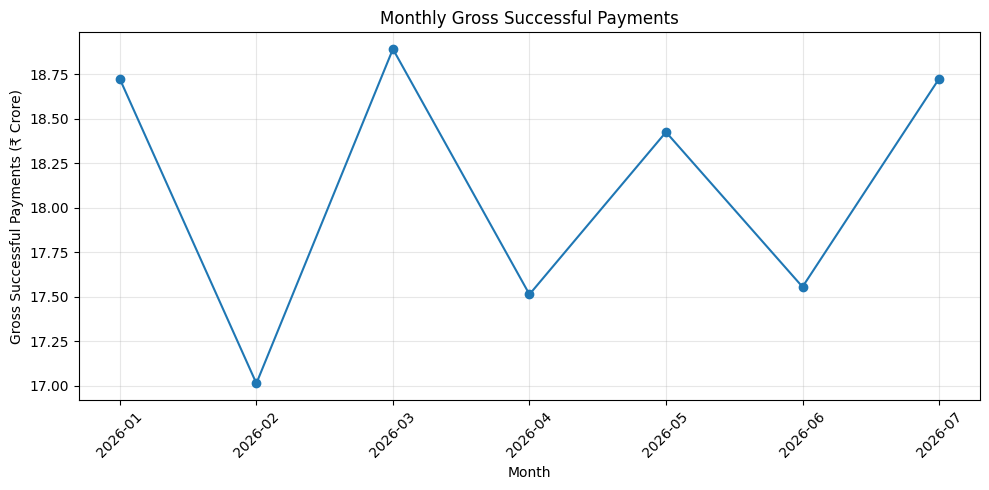

In [64]:
import matplotlib.pyplot as plt

complete_months = monthly_recovery[
    monthly_recovery["month"] <= "2026-07"
]

plt.figure(figsize=(10, 5))
plt.plot(
    complete_months["month"],
    complete_months["amount_crore"],
    marker="o"
)

plt.title("Monthly Gross Successful Payments")
plt.xlabel("Month")
plt.ylabel("Gross Successful Payments (₹ Crore)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

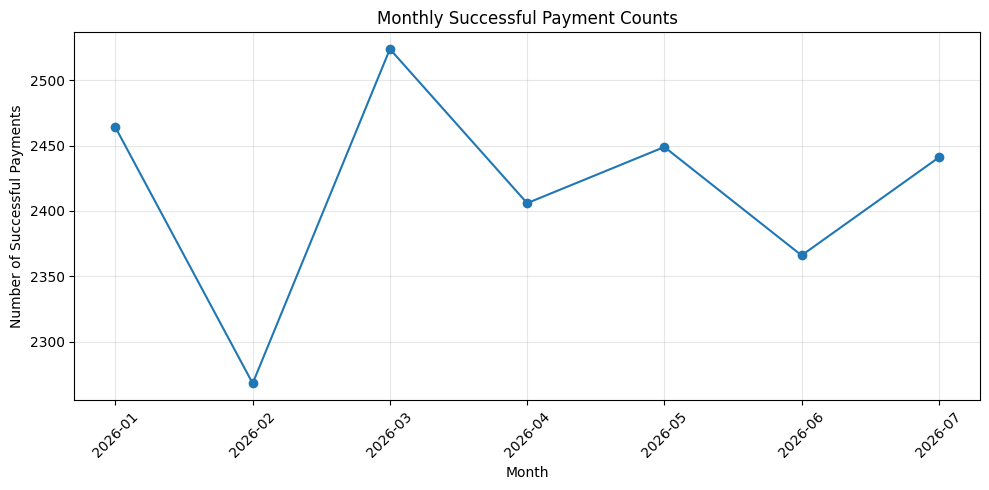

In [65]:
plt.figure(figsize=(10, 5))

plt.plot(
    complete_months["month"],
    complete_months["successful_payment_count"],
    marker="o"
)

plt.title("Monthly Successful Payment Counts")
plt.xlabel("Month")
plt.ylabel("Number of Successful Payments")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [66]:
monthly_recovery["average_payment_inr"] = (
    monthly_recovery["gross_successful_amount"]
    / monthly_recovery["successful_payment_count"]
)

display(
    monthly_recovery[
        [
            "month",
            "successful_payment_count",
            "amount_crore",
            "average_payment_inr"
        ]
    ].round(2)
)

,month,successful_payment_count,amount_crore,average_payment_inr
0,2026-01,2464,18.72,75985.85
1,2026-02,2268,17.01,75018.72
2,2026-03,2524,18.89,74846.42
3,2026-04,2406,17.51,72792.20
4,2026-05,2449,18.43,75234.90
5,2026-06,2366,17.56,74201.07
6,2026-07,2441,18.72,76707.20
7,2026-08,616,4.71,76476.78


In [67]:
complete_months = monthly_recovery[
    monthly_recovery["month"] <= "2026-07"
].copy()

jan = complete_months.iloc[0]
jul = complete_months.iloc[-1]

comparison = pd.DataFrame({
    "metric": [
        "Successful payment count",
        "Gross successful payment amount (₹ crore)",
        "Average successful payment amount (₹)"
    ],
    "January": [
        jan["successful_payment_count"],
        jan["amount_crore"],
        jan["average_payment_inr"]
    ],
    "July": [
        jul["successful_payment_count"],
        jul["amount_crore"],
        jul["average_payment_inr"]
    ]
})

comparison["change_pct"] = (
    (comparison["July"] - comparison["January"])
    / comparison["January"] * 100
)

display(comparison.round(2))

,metric,January,July,change_pct
0,Successful payment count,2464.00,2441.00,-0.93
1,Gross successful payment amount (₹ crore),18.72,18.72,0.01
2,Average successful payment amount (₹),75985.85,76707.20,0.95


In [68]:
monthly_recovery.to_csv(
    output_dir / "monthly_recovery_analysis.csv",
    index=False
)

comparison.to_csv(
    output_dir / "jan_jul_recovery_comparison.csv",
    index=False
)

print("Saved files:")
print(output_dir / "monthly_recovery_analysis.csv")
print(output_dir / "jan_jul_recovery_comparison.csv")

Saved files:
C:\Users\GOPICHAND\Desktop\CredResolve\outputs\monthly_recovery_analysis.csv
C:\Users\GOPICHAND\Desktop\CredResolve\outputs\jan_jul_recovery_comparison.csv


In [69]:
print("Files currently in the outputs folder:\n")

for file in sorted(output_dir.iterdir()):
    if file.is_file():
        print(f"{file.name} — {file.stat().st_size / 1024:.1f} KB")

Files currently in the outputs folder:

architecture_diagram.png — 117.7 KB
ceo_dashboard.png — 279.0 KB
cleaning_rules.csv — 0.9 KB
CredResolve_Executive_Memo.docx — 39.2 KB
data_quality_report.csv — 1.5 KB
golden_accounts.csv — 4062.9 KB
investment_evidence.csv — 0.6 KB
jan_jul_recovery_comparison.csv — 0.3 KB
monthly_recovery_analysis.csv — 0.7 KB
payment_method_analysis.csv — 0.2 KB
payment_reconciliation_findings.csv — 0.6 KB


In [70]:
print("Available staging tables:")
print(sorted(staging_data.keys()))

print("\nAvailable analysis objects:")
for name in [
    "monthly_recovery",
    "comparison",
    "scenario_clean",
    "provider_named",
    "calls_with_channel"
]:
    print(f"{name}: {'Available' if name in globals() else 'Not available'}")

Available staging tables:
['account_status_history', 'accounts', 'agent_sessions', 'agents', 'borrowers', 'call_attempts', 'call_dispositions', 'calls', 'campaigns', 'complaints', 'daily_targeting', 'data_dictionary', 'field_visits', 'payments', 'promises_to_pay', 'sms_events', 'vendor_telephony', 'whatsapp_events']

Available analysis objects:
monthly_recovery: Available
comparison: Available
scenario_clean: Available
provider_named: Available
calls_with_channel: Available


In [71]:
investment_evidence = pd.DataFrame([
    {
        "finding": "January-July gross payment change",
        "result": "+0.01%",
        "evidence_type": "Fact",
        "implication": "No sustained improvement demonstrated"
    },
    {
        "finding": "February-March gross payment change",
        "result": "+11.03%",
        "evidence_type": "Fact",
        "implication": "One-month increase; not a sustained trend"
    },
    {
        "finding": "Historical gross successful payments",
        "result": "₹131.56 crore",
        "evidence_type": "Fact",
        "implication": "Gross amount, not verified net recovery"
    },
    {
        "finding": "Payment reversal reconciliation",
        "result": "Unresolved",
        "evidence_type": "Data limitation",
        "implication": "Net recovery cannot be reliably calculated"
    },
    {
        "finding": "Collection and vendor costs",
        "result": "Unavailable",
        "evidence_type": "Data limitation",
        "implication": "Actual ROI and break-even remain unknown"
    },
    {
        "finding": "Illustrative 10% gross payment increase",
        "result": "₹13.16 crore",
        "evidence_type": "Hypothesis",
        "implication": "Not a forecast or proven investment return"
    }
])

display(investment_evidence)

,finding,result,evidence_type,implication
0,January-July gross payment change,+0.01%,Fact,No sustained improvement demonstrated
1,February-March gross payment change,+11.03%,Fact,One-month increase; not a sustained trend
2,Historical gross successful payments,₹131.56 crore,Fact,"Gross amount, not verified net recovery"
3,Payment reversal reconciliation,Unresolved,Data limitation,Net recovery cannot be reliably calculated
4,Collection and vendor costs,Unavailable,Data limitation,Actual ROI and break-even remain unknown
5,Illustrative 10% gross payment increase,₹13.16 crore,Hypothesis,Not a forecast or proven investment return


In [72]:
investment_evidence.to_csv(
    output_dir / "investment_evidence.csv",
    index=False
)

print("Investment evidence saved successfully.")
print(output_dir / "investment_evidence.csv")

Investment evidence saved successfully.
C:\Users\GOPICHAND\Desktop\CredResolve\outputs\investment_evidence.csv


## 9. Monthly KPIs and executive dashboard

Calculate complete-month summaries and generate the CEO-facing dashboard. The dashboard should make the partial August period and gross-payment limitation clear.

In [73]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_dir = PROJECT_DIR
output_dir = project_dir / "outputs"

monthly_recovery = pd.read_csv(
    output_dir / "monthly_recovery_analysis.csv"
)

monthly_recovery

,month,successful_payment_count,gross_successful_amount,amount_crore,mom_change_pct,average_payment_inr
0,2026-01,2464,1.872291e+08,18.722913,NaN,75985.847236
1,2026-02,2268,1.701425e+08,17.014245,-9.126077,75018.718589
2,2026-03,2524,1.889124e+08,18.891237,11.031885,74846.423938
3,2026-04,2406,1.751380e+08,17.513804,-7.291386,72792.204244
4,2026-05,2449,1.842503e+08,18.425028,5.202887,75234.903430
5,2026-06,2366,1.755597e+08,17.555973,-4.716710,74201.068035
6,2026-07,2441,1.872423e+08,18.724227,6.654452,76707.195854
7,2026-08,616,4.710970e+07,4.710970,-74.840245,76476.778101


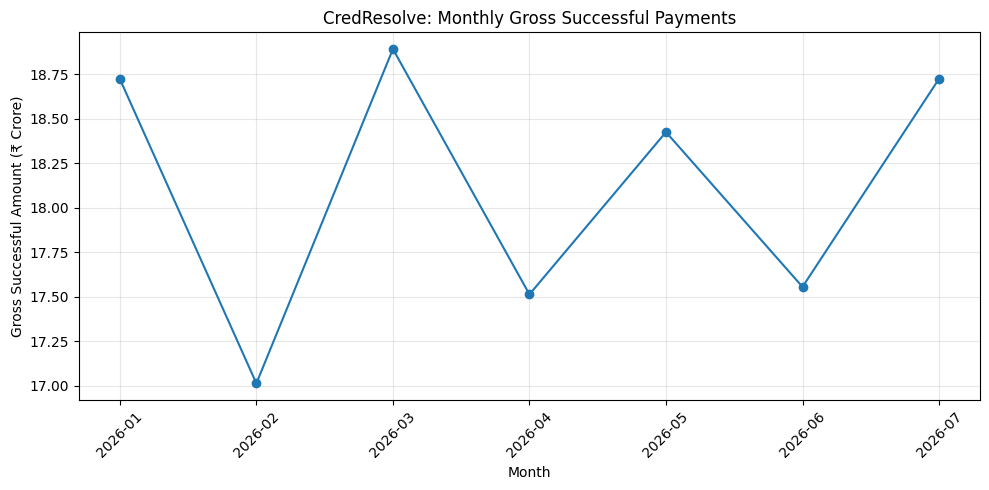

In [74]:
# Exclude August because it contains only partial-month data
complete_months = monthly_recovery[
    monthly_recovery["month"] <= "2026-07"
].copy()

plt.figure(figsize=(10, 5))

plt.plot(
    complete_months["month"],
    complete_months["amount_crore"],
    marker="o"
)

plt.title("CredResolve: Monthly Gross Successful Payments")
plt.xlabel("Month")
plt.ylabel("Gross Successful Amount (₹ Crore)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

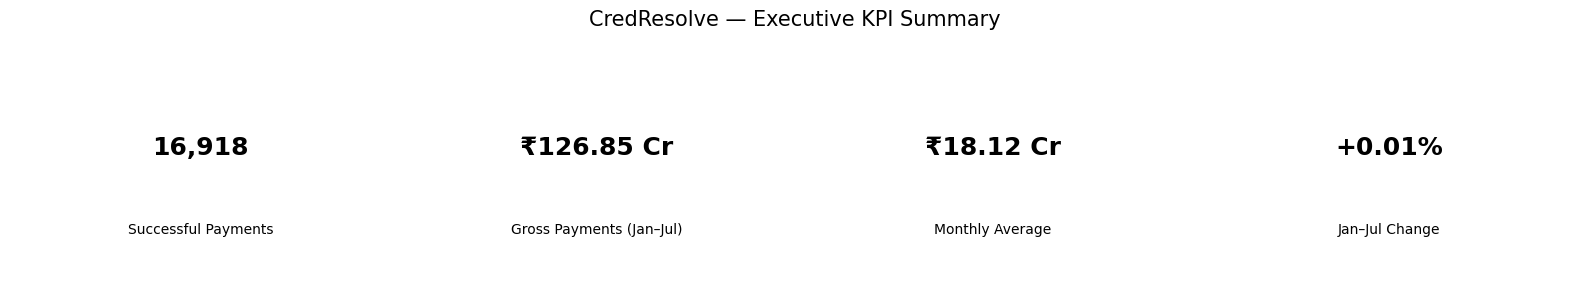

In [75]:
# Calculate key performance indicators
total_successful_payments = complete_months["successful_payment_count"].sum()

total_gross_recovery_crore = complete_months["amount_crore"].sum()

average_monthly_recovery_crore = complete_months["amount_crore"].mean()

jan_to_july_change = (
    (complete_months.iloc[-1]["amount_crore"] /
     complete_months.iloc[0]["amount_crore"]) - 1
) * 100

# Display KPI cards
fig, axes = plt.subplots(1, 4, figsize=(16, 3))

kpis = [
    ("Successful Payments", f"{total_successful_payments:,.0f}"),
    ("Gross Payments (Jan–Jul)", f"₹{total_gross_recovery_crore:.2f} Cr"),
    ("Monthly Average", f"₹{average_monthly_recovery_crore:.2f} Cr"),
    ("Jan–Jul Change", f"{jan_to_july_change:+.2f}%")
]

for ax, (title, value) in zip(axes, kpis):
    ax.text(0.5, 0.60, value, ha="center", va="center",
            fontsize=18, fontweight="bold")
    ax.text(0.5, 0.25, title, ha="center", va="center",
            fontsize=10, wrap=True)
    ax.set_axis_off()

plt.suptitle("CredResolve — Executive KPI Summary", fontsize=15)
plt.tight_layout()
plt.show()

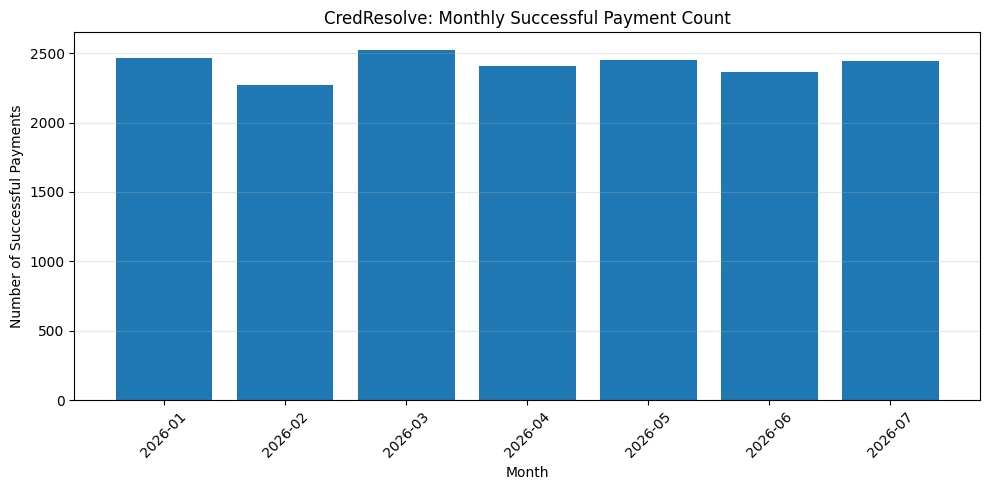

In [76]:
plt.figure(figsize=(10, 5))

plt.bar(
    complete_months["month"],
    complete_months["successful_payment_count"]
)

plt.title("CredResolve: Monthly Successful Payment Count")
plt.xlabel("Month")
plt.ylabel("Number of Successful Payments")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [77]:
payments_df = staging_data["payments"].copy()

print("Available columns:")
print(payments_df.columns.tolist())

Available columns:
['payment_id', 'account_id', 'borrower_id', 'event_at', 'payment_reference', 'amount', 'payment_status', 'payment_method', 'provider_id']


,payment_method,total_payments,successful_payments,success_rate_pct
2,NACH,5061,3600,71.13
3,NETBANKING,4960,3527,71.11
1,CASH,4893,3434,70.18
0,CARD,5121,3560,69.52
4,UPI,4965,3413,68.74


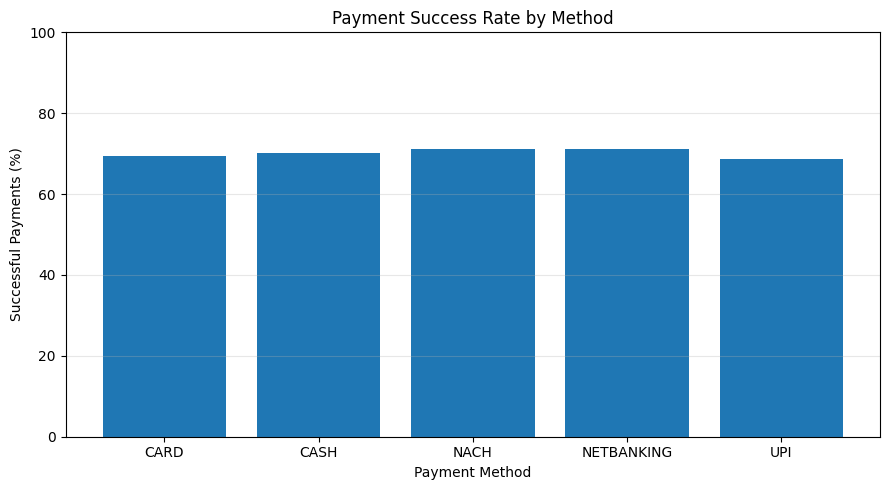

In [78]:
payments_df = staging_data["payments"].copy()

payments_df["payment_status"] = (
    payments_df["payment_status"]
    .astype(str)
    .str.upper()
    .str.strip()
)

method_summary = (
    payments_df.groupby("payment_method")
    .agg(
        total_payments=("payment_id", "nunique"),
        successful_payments=(
            "payment_status",
            lambda s: (s == "SUCCESS").sum()
        )
    )
    .reset_index()
)

method_summary["success_rate_pct"] = (
    method_summary["successful_payments"]
    / method_summary["total_payments"] * 100
)

display(
    method_summary.sort_values(
        "success_rate_pct", ascending=False
    ).round(2)
)

plt.figure(figsize=(9, 5))

plt.bar(
    method_summary["payment_method"],
    method_summary["success_rate_pct"]
)

plt.title("Payment Success Rate by Method")
plt.xlabel("Payment Method")
plt.ylabel("Successful Payments (%)")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [79]:
method_summary = method_summary.sort_values(
    "success_rate_pct", ascending=False
)

method_summary.to_csv(
    output_dir / "payment_method_analysis.csv",
    index=False
)

print("Saved payment-method analysis to:")
print(output_dir / "payment_method_analysis.csv")

Saved payment-method analysis to:
C:\Users\GOPICHAND\Desktop\CredResolve\outputs\payment_method_analysis.csv


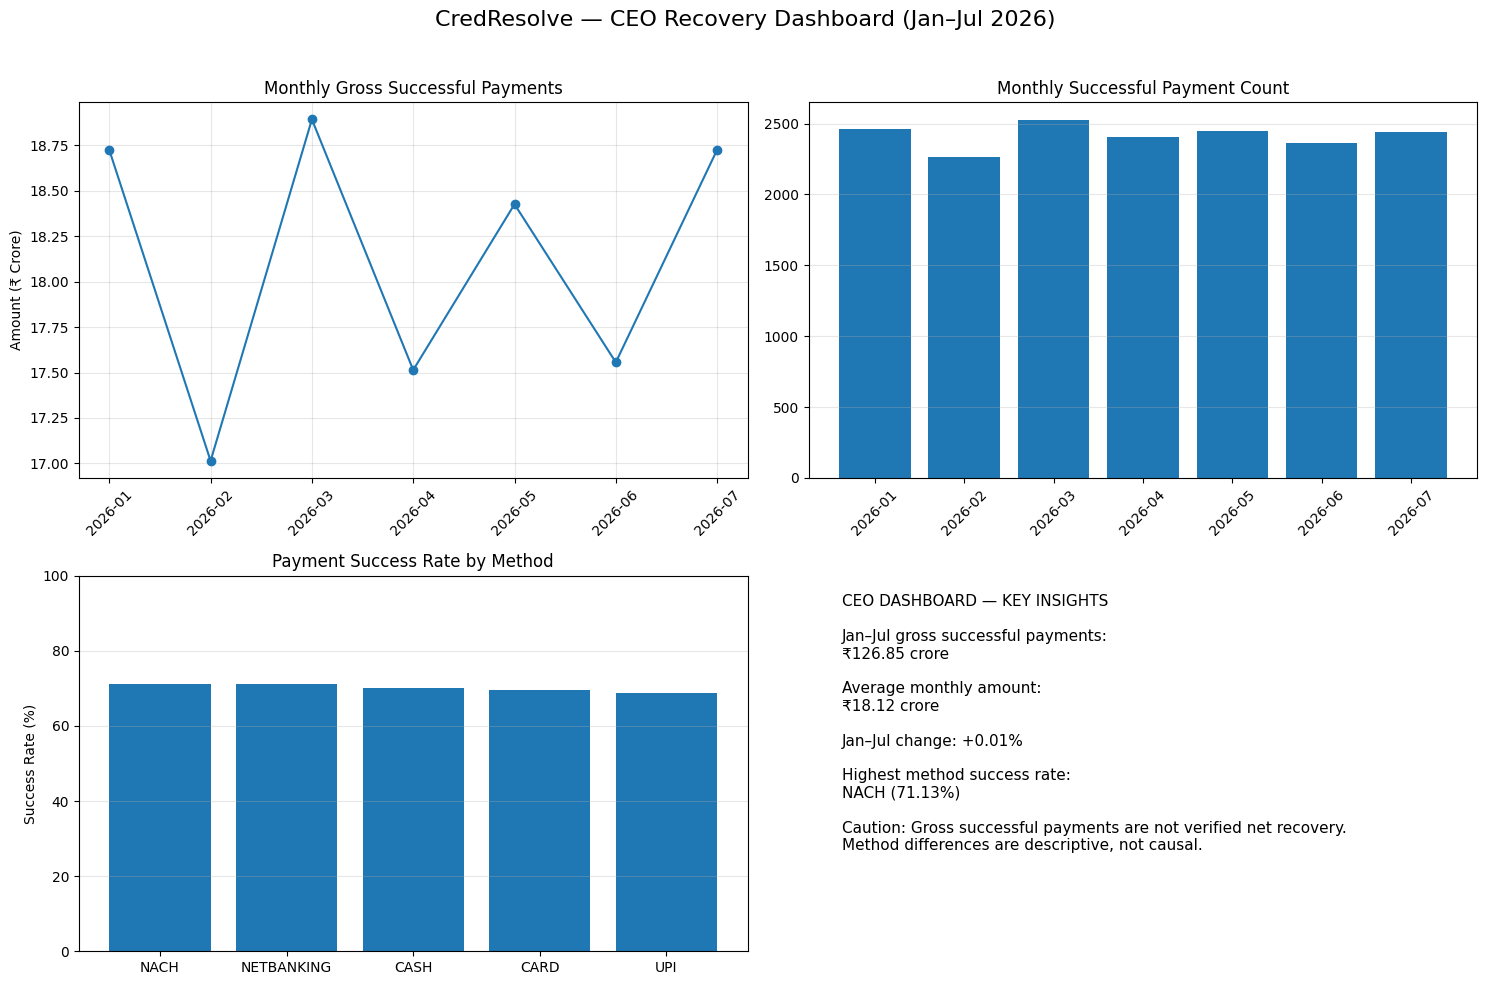

Dashboard saved to: C:\Users\GOPICHAND\Desktop\CredResolve\outputs\ceo_dashboard.png


In [80]:
# Create the CEO dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Monthly gross successful payments
axes[0, 0].plot(
    complete_months["month"],
    complete_months["amount_crore"],
    marker="o"
)
axes[0, 0].set_title("Monthly Gross Successful Payments")
axes[0, 0].set_ylabel("Amount (₹ Crore)")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(True, alpha=0.3)

# 2. Monthly successful payment count
axes[0, 1].bar(
    complete_months["month"],
    complete_months["successful_payment_count"]
)
axes[0, 1].set_title("Monthly Successful Payment Count")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].grid(axis="y", alpha=0.3)

# 3. Success rate by payment method
axes[1, 0].bar(
    method_summary["payment_method"],
    method_summary["success_rate_pct"]
)
axes[1, 0].set_title("Payment Success Rate by Method")
axes[1, 0].set_ylabel("Success Rate (%)")
axes[1, 0].set_ylim(0, 100)
axes[1, 0].grid(axis="y", alpha=0.3)

# 4. Executive insight
axes[1, 1].axis("off")

dashboard_text = (
    "CEO DASHBOARD — KEY INSIGHTS\n\n"
    f"Jan–Jul gross successful payments:\n"
    f"₹{complete_months['amount_crore'].sum():.2f} crore\n\n"
    f"Average monthly amount:\n"
    f"₹{complete_months['amount_crore'].mean():.2f} crore\n\n"
    f"Jan–Jul change: {jan_to_july_change:+.2f}%\n\n"
    "Highest method success rate:\n"
    f"{method_summary.iloc[0]['payment_method']} "
    f"({method_summary.iloc[0]['success_rate_pct']:.2f}%)\n\n"
    "Caution: Gross successful payments are not verified net recovery.\n"
    "Method differences are descriptive, not causal."
)

axes[1, 1].text(
    0.05, 0.95,
    dashboard_text,
    va="top",
    fontsize=11,
    wrap=True
)

fig.suptitle(
    "CredResolve — CEO Recovery Dashboard (Jan–Jul 2026)",
    fontsize=16
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

# Save the dashboard image
dashboard_path = output_dir / "ceo_dashboard.png"
plt.savefig(dashboard_path, dpi=200, bbox_inches="tight")
plt.show()

print("Dashboard saved to:", dashboard_path)

In [81]:
sql_dir = project_dir / "sql"
sql_dir.mkdir(parents=True, exist_ok=True)

sql_script = """
-- CredResolve: Monthly Recovery Analysis
-- Purpose: Summarize successful payment records by month.
-- Note: This reports gross successful payments, not net recovery.

SELECT
    SUBSTR(event_at, 1, 7) AS month,
    COUNT(DISTINCT payment_id) AS successful_payment_count,
    SUM(amount) AS gross_successful_amount
FROM payments
WHERE UPPER(TRIM(payment_status)) = 'SUCCESS'
GROUP BY SUBSTR(event_at, 1, 7)
ORDER BY month;
"""

sql_file = sql_dir / "01_monthly_recovery.sql"
sql_file.write_text(sql_script.strip() + "\n", encoding="utf-8")

print("Created:", sql_file)

Created: C:\Users\GOPICHAND\Desktop\CredResolve\sql\01_monthly_recovery.sql


In [82]:
readme_text = """
# CredResolve SQL Repository

## Purpose
This folder contains SQL scripts for reproducible analysis
of the CredResolve synthetic collections dataset.

## Files
- 01_monthly_recovery.sql:
  Summarizes monthly successful payment records and gross amounts.

## Required table
The query expects a table named `payments` with these columns:
- payment_id
- event_at
- amount
- payment_status

## Important limitations
- The SQL assumes the payments table has already been loaded.
- The query reports gross successful payment amounts, not net recovery.
- Reversed payments cannot currently be reliably matched to their
  original successful payments.
- August 2026 is a partial month in the supplied data.
- Results depend on the SQL database and timestamp format used.

## Reproducibility
Load the payments dataset into a compatible SQL database, check
that the column names and timestamp format match the query, and
execute 01_monthly_recovery.sql.

Validate the SQL output against:
../outputs/monthly_recovery_analysis.csv
"""

readme_path = sql_dir / "README.md"
readme_path.write_text(readme_text.strip() + "\n", encoding="utf-8")

print("Created:", readme_path)

Created: C:\Users\GOPICHAND\Desktop\CredResolve\sql\README.md


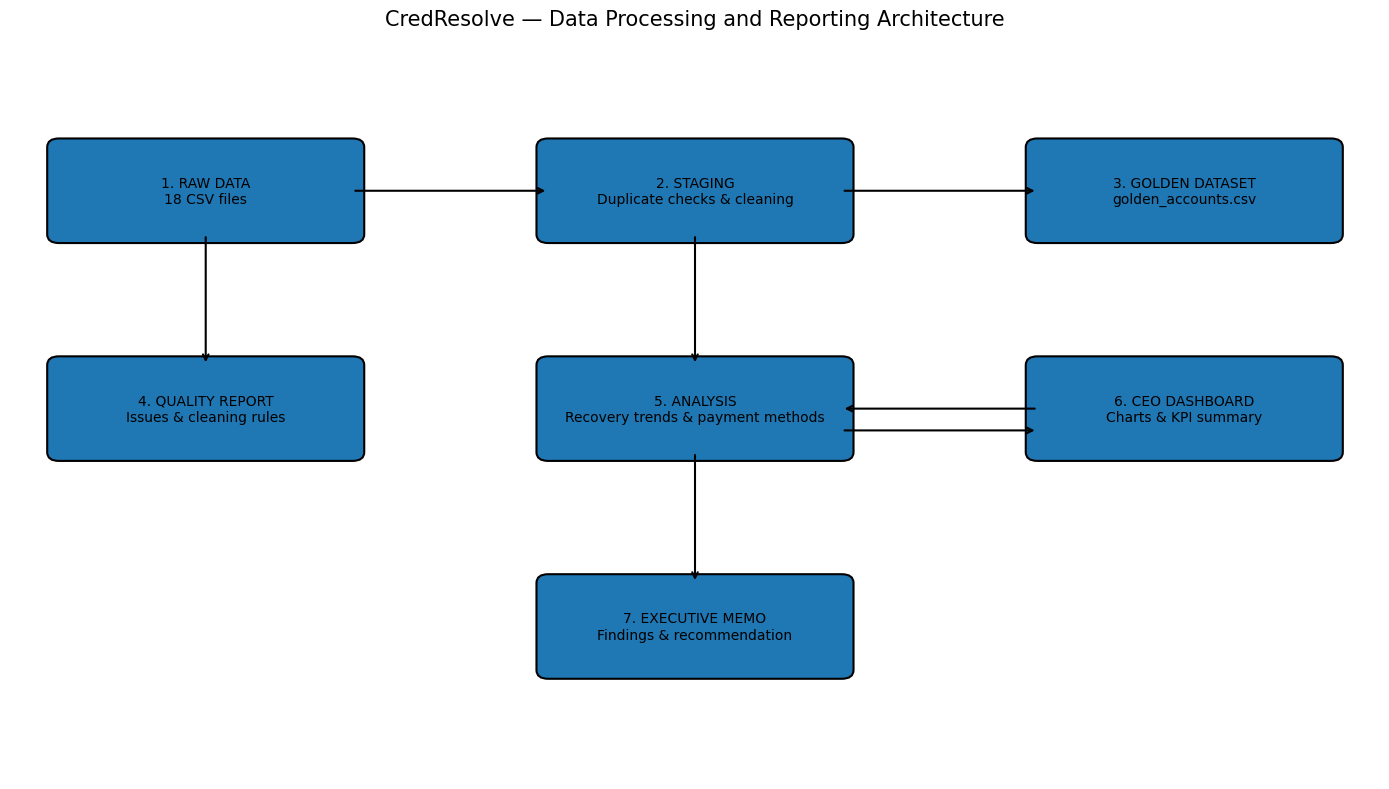

Architecture diagram saved to: C:\Users\GOPICHAND\Desktop\CredResolve\outputs\architecture_diagram.png


In [83]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 8))
ax.set_xlim(0, 14)
ax.set_ylim(0, 10)
ax.axis("off")

boxes = [
    (0.5, 7.5, 3, 1.2, "1. RAW DATA\n18 CSV files"),
    (5.5, 7.5, 3, 1.2, "2. STAGING\nDuplicate checks & cleaning"),
    (10.5, 7.5, 3, 1.2, "3. GOLDEN DATASET\ngolden_accounts.csv"),
    (0.5, 4.5, 3, 1.2, "4. QUALITY REPORT\nIssues & cleaning rules"),
    (5.5, 4.5, 3, 1.2, "5. ANALYSIS\nRecovery trends & payment methods"),
    (10.5, 4.5, 3, 1.2, "6. CEO DASHBOARD\nCharts & KPI summary"),
    (5.5, 1.5, 3, 1.2, "7. EXECUTIVE MEMO\nFindings & recommendation"),
]

for x, y, w, h, label in boxes:
    box = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.12",
        linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(
        x + w / 2, y + h / 2,
        label,
        ha="center", va="center",
        fontsize=10, wrap=True
    )

# Main data flow
arrows = [
    ((3.5, 8.1), (5.5, 8.1)),
    ((8.5, 8.1), (10.5, 8.1)),
    ((2, 7.5), (2, 5.7)),
    ((7, 7.5), (7, 5.7)),
    ((10.5, 5.1), (8.5, 5.1)),
    ((8.5, 4.8), (10.5, 4.8)),
    ((7, 4.5), (7, 2.7)),
]

for start, end in arrows:
    ax.annotate(
        "",
        xy=end, xytext=start,
        arrowprops=dict(arrowstyle="->", linewidth=1.5)
    )

ax.set_title(
    "CredResolve — Data Processing and Reporting Architecture",
    fontsize=15, pad=20
)

plt.tight_layout()

architecture_path = output_dir / "architecture_diagram.png"
plt.savefig(architecture_path, dpi=200, bbox_inches="tight")
plt.show()

print("Architecture diagram saved to:", architecture_path)

## 10. Portfolio and borrower characteristics

Explore account/borrower composition and geography where data quality supports comparison. Separate observed differences from causal explanations.

In [84]:
# Inspect the datasets available for deeper investigation

tables_to_check = [
    "accounts",
    "borrowers",
    "calls",
    "call_attempts",
    "call_dispositions",
    "agent_sessions",
    "campaigns",
    "daily_targeting",
    "payments",
    "promises_to_pay",
    "field_visits",
    "whatsapp_events",
    "sms_events",
]

for table_name in tables_to_check:
    if table_name in staging_data:
        df = staging_data[table_name]
        print(f"\n{'=' * 60}")
        print(f"TABLE: {table_name}")
        print(f"Rows: {len(df):,}")
        print("Columns:", df.columns.tolist())


TABLE: accounts
Rows: 30,000
Columns: ['account_id', 'borrower_id', 'loan_type', 'principal_amount', 'outstanding_amount', 'dpd', 'risk_segment', 'status', 'opened_at', 'timezone', 'schema_version']

TABLE: borrowers
Rows: 30,000
Columns: ['borrower_id', 'name', 'phone', 'email', 'city', 'created_at', 'updated_at', 'state']

TABLE: calls
Rows: 90,011
Columns: ['call_id', 'account_id', 'borrower_id', 'event_at', 'agent_id', 'campaign_id', 'direction', 'vendor_id', 'call_status', 'duration_sec', 'timezone']

TABLE: call_attempts
Rows: 120,000
Columns: ['attempt_id', 'account_id', 'borrower_id', 'event_at', 'call_id', 'agent_id', 'attempt_no', 'vendor_id', 'attempt_status']

TABLE: call_dispositions
Rows: 35,000
Columns: ['disposition_id', 'account_id', 'borrower_id', 'event_at', 'call_id', 'agent_id', 'disposition_code', 'disposition_version']

TABLE: agent_sessions
Rows: 15,000
Columns: ['session_id', 'agent_id', 'login_at', 'channel', 'device_id', 'timezone', 'logout_at']

TABLE: camp

In [85]:
# Investigate portfolio composition and borrower geography

print("BORROWER GEOGRAPHY")
print("\nTop 15 cities:")
print(staging_data["borrowers"]["city"].value_counts(dropna=False).head(15))

print("\nTop 15 states:")
print(staging_data["borrowers"]["state"].value_counts(dropna=False).head(15))

print("\nLOAN TYPE DISTRIBUTION")
print(staging_data["accounts"]["loan_type"].value_counts(dropna=False))

print("\nRISK SEGMENT DISTRIBUTION")
print(staging_data["accounts"]["risk_segment"].value_counts(dropna=False))

print("\nDPD DISTRIBUTION")
print(
    staging_data["accounts"]["dpd"]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.90])
    .round(2)
)

print("\nACCOUNT STATUS DISTRIBUTION")
print(staging_data["accounts"]["status"].value_counts(dropna=False))

print("\nTIMEZONE DISTRIBUTION")
print(staging_data["accounts"]["timezone"].value_counts(dropna=False))

BORROWER GEOGRAPHY

Top 15 cities:
city
Delhi          3105
Hyderabad      3061
Pune           3041
Bhubaneswar    3041
Chennai        3016
Bengaluru      3010
Gurugram       2982
Mumbai         2943
Jaipur         2941
Kolkata        2860
Name: count, dtype: int64

Top 15 states:
state
Maharashtra    5984
Delhi          3105
Telangana      3061
Odisha         3041
Tamil Nadu     3016
Karnataka      3010
Haryana        2982
Rajasthan      2941
West Bengal    2860
Name: count, dtype: int64

LOAN TYPE DISTRIBUTION
loan_type
CREDIT_CARD    6080
AUTO           6079
PERSONAL       5983
CONSUMER       5930
BNPL           5928
Name: count, dtype: int64

RISK SEGMENT DISTRIBUTION
risk_segment
HIGH      7552
MEDIUM    7533
LOW       7513
NPA       7402
Name: count, dtype: int64

DPD DISTRIBUTION
count    30000.00
mean        56.51
std         53.97
min          0.00
25%          5.00
50%         45.00
75%         90.00
90%        120.00
max        180.00
Name: dpd, dtype: float64

ACCOUNT STATU

In [86]:
import pandas as pd

# Successful payment totals by account
payments = staging_data["payments"].copy()
payments["payment_status"] = payments["payment_status"].astype(str).str.strip().str.upper()

successful = payments[payments["payment_status"] == "SUCCESS"].copy()

account_payments = (
    successful.groupby("account_id")
    .agg(
        successful_payment_count=("payment_id", "nunique"),
        successful_payment_amount=("amount", "sum")
    )
    .reset_index()
)

# Combine with account-level portfolio data
accounts = staging_data["accounts"].copy()
analysis_df = accounts.merge(
    account_payments,
    on="account_id",
    how="left",
    validate="one_to_one"
)

analysis_df[["successful_payment_count", "successful_payment_amount"]] = (
    analysis_df[["successful_payment_count", "successful_payment_amount"]]
    .fillna(0)
)

analysis_df["dpd_band"] = pd.cut(
    analysis_df["dpd"],
    bins=[-1, 0, 30, 60, 90, 180],
    labels=["0 days", "1–30", "31–60", "61–90", "91–180"]
)

print("RECOVERY BY LOAN TYPE")
print(
    analysis_df.groupby("loan_type", observed=True)
    .agg(
        accounts=("account_id", "nunique"),
        accounts_with_successful_payments=(
            "successful_payment_count",
            lambda x: (x > 0).sum()
        ),
        gross_successful_amount=("successful_payment_amount", "sum"),
        avg_successful_amount_per_account=("successful_payment_amount", "mean")
    )
    .round(2)
)

print("\nRECOVERY BY DPD BAND")
print(
    analysis_df.groupby("dpd_band", observed=True)
    .agg(
        accounts=("account_id", "nunique"),
        accounts_with_successful_payments=(
            "successful_payment_count",
            lambda x: (x > 0).sum()
        ),
        gross_successful_amount=("successful_payment_amount", "sum"),
        avg_successful_amount_per_account=("successful_payment_amount", "mean")
    )
    .round(2)
)

RECOVERY BY LOAN TYPE
             accounts  accounts_with_successful_payments  \
loan_type                                                  
AUTO             6079                               2700   
BNPL             5928                               2580   
CONSUMER         5930                               2685   
CREDIT_CARD      6080                               2690   
PERSONAL         5983                               2629   

             gross_successful_amount  avg_successful_amount_per_account  
loan_type                                                                
AUTO                    2.679332e+08                           44075.21  
BNPL                    2.554400e+08                           43090.42  
CONSUMER                2.669767e+08                           45021.36  
CREDIT_CARD             2.686432e+08                           44184.74  
PERSONAL                2.565909e+08                           42886.66  

RECOVERY BY DPD BAND
          account

## 11. Channel, digital engagement, and PTP analysis

Compare contact/engagement and payment outcomes. Use clear denominators and treat engagement-to-payment relationships as correlation unless properly identified.

In [87]:
attempts = staging_data["call_attempts"].copy()

print("ATTEMPT STATUS DISTRIBUTION")
print(attempts["attempt_status"].value_counts(dropna=False))

print("\nATTEMPTS PER ACCOUNT")
attempts_per_account = attempts.groupby("account_id").size()

print(attempts_per_account.describe(percentiles=[0.5, 0.75, 0.9, 0.95]).round(2))

print("\nATTEMPT NUMBER DISTRIBUTION")
print(attempts["attempt_no"].value_counts(dropna=False).sort_index())

print("\nATTEMPT STATUS BY ATTEMPT NUMBER")
print(pd.crosstab(
    attempts["attempt_no"],
    attempts["attempt_status"],
    normalize="index"
).round(3))

print("\nCALL STATUS DISTRIBUTION")
print(staging_data["calls"]["call_status"].value_counts(dropna=False))

ATTEMPT STATUS DISTRIBUTION
attempt_status
RINGING      24087
NO_ANSWER    24042
BUSY         24037
CONNECTED    24023
FAILED       23811
Name: count, dtype: int64

ATTEMPTS PER ACCOUNT
count    29451.00
mean         4.07
std          1.94
min          1.00
50%          4.00
75%          5.00
90%          7.00
95%          8.00
max         16.00
dtype: float64

ATTEMPT NUMBER DISTRIBUTION
attempt_no
1    17089
2    17100
3    17201
4    17252
5    16952
6    17207
7    17199
Name: count, dtype: int64

ATTEMPT STATUS BY ATTEMPT NUMBER
attempt_status   BUSY  CONNECTED  FAILED  NO_ANSWER  RINGING
attempt_no                                                  
1               0.201      0.203   0.195      0.202    0.200
2               0.203      0.198   0.199      0.198    0.202
3               0.201      0.206   0.198      0.198    0.198
4               0.197      0.201   0.197      0.204    0.201
5               0.199      0.201   0.201      0.197    0.201
6               0.202      0.194 

In [88]:
# Digital engagement analysis

for table_name in ["whatsapp_events", "sms_events"]:
    df = staging_data[table_name].copy()

    print(f"\n{'=' * 50}")
    print(f"{table_name.upper()}")

    print("\nEvent type distribution:")
    print(df["event_type"].value_counts(dropna=False))

    print("\nTemplate distribution (top 10):")
    print(df["template_code"].value_counts(dropna=False).head(10))

    print("\nEvents per account:")
    events_per_account = df.groupby("account_id").size()
    print(
        events_per_account.describe(
            percentiles=[0.5, 0.75, 0.9, 0.95]
        ).round(2)
    )

    print("\nUnique accounts:", df["account_id"].nunique())
    print("Unique message IDs:", df["message_id"].nunique())
    print("Missing event types:", df["event_type"].isna().sum())


WHATSAPP_EVENTS

Event type distribution:
event_type
SENT             10145
PAYMENT_CLICK    10056
FAILED           10029
REPLIED           9935
READ              9928
DELIVERED         9907
Name: count, dtype: int64

Template distribution (top 10):
template_code
PTP_01          12153
FIELD_VISIT     12059
PAYMENT_LINK    12017
LEGAL_NOTICE    11951
REMINDER_01     11820
Name: count, dtype: int64

Events per account:
count    25924.00
mean         2.31
std          1.26
min          1.00
50%          2.00
75%          3.00
90%          4.00
95%          5.00
max         11.00
dtype: float64

Unique accounts: 25924
Unique message IDs: 34831
Missing event types: 0

SMS_EVENTS

Event type distribution:
event_type
SENT         11391
FAILED       11251
DELIVERED    11219
CLICKED      11139
Name: count, dtype: int64

Template distribution (top 10):
template_code
PAYMENT_LINK    11420
DUE_REMINDER    11256
NOTICE          11166
PTP_REMINDER    11158
Name: count, dtype: int64

Events per acco

In [89]:
# Compare digital engagement with successful payments

payments = staging_data["payments"].copy()
payments["payment_status"] = (
    payments["payment_status"].astype(str).str.strip().str.upper()
)

successful_accounts = set(
    payments.loc[
        payments["payment_status"] == "SUCCESS", "account_id"
    ].dropna()
)

for table_name, click_event in [
    ("whatsapp_events", "PAYMENT_CLICK"),
    ("sms_events", "CLICKED"),
]:
    events = staging_data[table_name].copy()

    events["event_type"] = (
        events["event_type"].astype(str).str.strip().str.upper()
    )

    clicked_accounts = set(
        events.loc[
            events["event_type"] == click_event, "account_id"
        ].dropna()
    )

    all_event_accounts = set(events["account_id"].dropna())

    groups = {
        "Recorded click": clicked_accounts,
        "No recorded click": all_event_accounts - clicked_accounts,
    }

    print(f"\n{'=' * 50}")
    print(table_name.upper())

    for group_name, account_ids in groups.items():
        paid_accounts = account_ids & successful_accounts

        print(f"\n{group_name}")
        print("Accounts:", len(account_ids))
        print("Accounts with successful payments:", len(paid_accounts))
        print(
            "Observed payment rate:",
            round(100 * len(paid_accounts) / len(account_ids), 2)
            if account_ids else 0,
            "%"
        )


WHATSAPP_EVENTS

Recorded click
Accounts: 8505
Accounts with successful payments: 3760
Observed payment rate: 44.21 %

No recorded click
Accounts: 17419
Accounts with successful payments: 7746
Observed payment rate: 44.47 %

SMS_EVENTS

Recorded click
Accounts: 9251
Accounts with successful payments: 4140
Observed payment rate: 44.75 %

No recorded click
Accounts: 13956
Accounts with successful payments: 6170
Observed payment rate: 44.21 %


In [90]:
ptp = staging_data["promises_to_pay"].copy()

print("PTP STATUS DISTRIBUTION")
print(ptp["status"].value_counts(dropna=False))

print("\nPTP SOURCE DISTRIBUTION")
print(ptp["source"].value_counts(dropna=False))

print("\nPROMISE AMOUNT SUMMARY")
print(ptp["promised_amount"].describe().round(2))

print("\nPROMISED DATE MISSING")
print(ptp["promised_date"].isna().sum())

print("\nPROMISE STATUS BY SOURCE")
print(pd.crosstab(
    ptp["source"],
    ptp["status"],
    normalize="index"
).round(3))

print("\nPROMISES PER ACCOUNT")
print(
    ptp.groupby("account_id")
    .size()
    .describe(percentiles=[0.5, 0.75, 0.9, 0.95])
    .round(2)
)

PTP STATUS DISTRIBUTION
status
BROKEN       4553
CANCELLED    4543
KEPT         4489
OPEN         4415
Name: count, dtype: int64

PTP SOURCE DISTRIBUTION
source
CALL        4571
FIELD       4546
SMS         4449
WHATSAPP    4434
Name: count, dtype: int64

PROMISE AMOUNT SUMMARY
count    18000.00
mean     50233.84
std      28631.75
min        511.99
25%      25441.33
50%      50312.00
75%      74975.03
max      99997.28
Name: promised_amount, dtype: float64

PROMISED DATE MISSING
0

PROMISE STATUS BY SOURCE
status    BROKEN  CANCELLED   KEPT   OPEN
source                                   
CALL       0.256      0.249  0.257  0.238
FIELD      0.253      0.255  0.245  0.247
SMS        0.257      0.247  0.256  0.241
WHATSAPP   0.246      0.259  0.239  0.256

PROMISES PER ACCOUNT
count    13532.00
mean         1.33
std          0.60
min          1.00
50%          1.00
75%          2.00
90%          2.00
95%          3.00
max          6.00
dtype: float64


In [91]:
# Check whether successful payments occur within 7 days of a promise

ptp = staging_data["promises_to_pay"].copy()
payments = staging_data["payments"].copy()

ptp["promised_date"] = pd.to_datetime(
    ptp["promised_date"], errors="coerce", utc=True
)

payments["payment_date"] = pd.to_datetime(
    payments["event_at"], errors="coerce", utc=True
)

payments["payment_status"] = (
    payments["payment_status"].astype(str).str.strip().str.upper()
)

successful = payments.loc[
    payments["payment_status"] == "SUCCESS",
    ["account_id", "payment_date", "amount"]
].copy()

# Match using account_id
matches = ptp.merge(
    successful,
    on="account_id",
    how="left"
)

matches["days_after_promise"] = (
    matches["payment_date"] - matches["promised_date"]
).dt.total_seconds() / 86400

matches["payment_within_7_days"] = (
    matches["days_after_promise"].between(0, 7, inclusive="both")
)

ptp_check = matches.groupby("ptp_id").agg(
    recorded_status=("status", "first"),
    payment_within_7_days=("payment_within_7_days", "max")
).reset_index()

print("RECORDED PTP STATUS")
print(ptp_check["recorded_status"].value_counts())

print("\nPAYMENT WITHIN 7 DAYS BY RECORDED STATUS")
print(
    ptp_check.groupby("recorded_status", dropna=False)
    .agg(
        promises=("ptp_id", "nunique"),
        payments_within_7_days=("payment_within_7_days", "sum")
    )
    .assign(
        fulfilment_rate_pct=lambda x: (
            100 * x["payments_within_7_days"] / x["promises"]
        ).round(2)
    )
)

RECORDED PTP STATUS
recorded_status
BROKEN       4553
CANCELLED    4543
KEPT         4489
OPEN         4415
Name: count, dtype: int64

PAYMENT WITHIN 7 DAYS BY RECORDED STATUS
                 promises  payments_within_7_days  fulfilment_rate_pct
recorded_status                                                       
BROKEN               4553                      80                 1.76
CANCELLED            4543                      85                 1.87
KEPT                 4489                      95                 2.12
OPEN                 4415                      86                 1.95


## 12. Time, field visits, and agent quality

Review local-time interpretation, field activity, agent identifiers, and session quality. Time-zone and identity issues can distort operational metrics.

In [92]:
# Analyse call timing using the recorded timezone

calls = staging_data["calls"].copy()

calls["event_at"] = pd.to_datetime(
    calls["event_at"], errors="coerce", utc=True
)

print("CALL TIMEZONE DISTRIBUTION")
print(calls["timezone"].value_counts(dropna=False))

# Extract UTC timing first; local-time comparisons require timezone validation.
calls["call_hour_utc"] = calls["event_at"].dt.hour
calls["call_day_utc"] = calls["event_at"].dt.day_name()

print("\nCALLS BY UTC HOUR")
print(calls["call_hour_utc"].value_counts().sort_index())

print("\nCALL STATUS BY UTC HOUR")
print(pd.crosstab(
    calls["call_hour_utc"],
    calls["call_status"],
    normalize="index"
).round(3))

print("\nCALLS BY UTC DAY OF WEEK")
print(calls["call_day_utc"].value_counts())

print("\nCALL STATUS BY UTC DAY")
print(pd.crosstab(
    calls["call_day_utc"],
    calls["call_status"],
    normalize="index"
).round(3))

CALL TIMEZONE DISTRIBUTION
timezone
Asia/Kolkata    30041
Asia/Dubai      30000
UTC             29970
Name: count, dtype: int64

CALLS BY UTC HOUR
call_hour_utc
0     3630
1     3745
2     3881
3     3775
4     3697
5     3798
6     3816
7     3793
8     3700
9     3699
10    3794
11    3846
12    3678
13    3812
14    3700
15    3642
16    3842
17    3631
18    3782
19    3775
20    3682
21    3716
22    3681
23    3896
Name: count, dtype: int64

CALL STATUS BY UTC HOUR
call_status    ANSWERED   BUSY  FAILED  NO_ANSWER  VOICEMAIL
call_hour_utc                                               
0                 0.203  0.196   0.197      0.201      0.203
1                 0.205  0.203   0.213      0.190      0.189
2                 0.186  0.199   0.205      0.204      0.206
3                 0.200  0.207   0.190      0.204      0.199
4                 0.202  0.206   0.197      0.188      0.207
5                 0.192  0.199   0.216      0.195      0.198
6                 0.198  0.207   0.2

In [93]:
visits = staging_data["field_visits"].copy()

print("VISIT OUTCOME DISTRIBUTION")
print(visits["outcome"].value_counts(dropna=False))

print("\nVISIT TYPE DISTRIBUTION")
print(visits["visit_type"].value_counts(dropna=False))

print("\nOUTCOMES BY VISIT TYPE")
print(pd.crosstab(
    visits["visit_type"],
    visits["outcome"],
    normalize="index"
).round(3))

print("\nVISITS PER ACCOUNT")
print(
    visits.groupby("account_id")
    .size()
    .describe(percentiles=[0.5, 0.75, 0.9, 0.95])
    .round(2)
)

print("\nSCHEDULED TIME MISSING")
print(visits["scheduled_at"].isna().sum())

print("\nLOCATION COORDINATE QUALITY")
print("Missing latitude:", visits["latitude"].isna().sum())
print("Missing longitude:", visits["longitude"].isna().sum())
print("Latitude range:", visits["latitude"].min(), "to", visits["latitude"].max())
print("Longitude range:", visits["longitude"].min(), "to", visits["longitude"].max())

VISIT OUTCOME DISTRIBUTION
outcome
WRONG_ADDRESS    4221
CONTACTED        4205
PTP              4200
NOT_AVAILABLE    4190
REFUSED          4104
PAID             4080
Name: count, dtype: int64

VISIT TYPE DISTRIBUTION
visit_type
FIRST_VISIT    6275
FOLLOWUP       6271
NOTICE         6262
AFTER_HOURS    6192
Name: count, dtype: int64

OUTCOMES BY VISIT TYPE
outcome      CONTACTED  NOT_AVAILABLE   PAID    PTP  REFUSED  WRONG_ADDRESS
visit_type                                                                 
AFTER_HOURS      0.172          0.168  0.163  0.164    0.167          0.166
FIRST_VISIT      0.165          0.161  0.167  0.169    0.166          0.171
FOLLOWUP         0.171          0.173  0.160  0.172    0.152          0.172
NOTICE           0.165          0.168  0.162  0.167    0.172          0.166

VISITS PER ACCOUNT
count    16908.00
mean         1.48
std          0.73
min          1.00
50%          1.00
75%          2.00
90%          2.00
95%          3.00
max          7.00
dty

In [94]:
# Agent identity and session quality checks

agents = staging_data["agents"].copy()
sessions = staging_data["agent_sessions"].copy()

print("AGENT TABLE")
print("Rows:", len(agents))
print("Unique agent IDs:", agents["agent_id"].nunique())

for col in ["employee_code", "name", "vendor_id"]:
    if col in agents.columns:
        print(f"\nDistinct {col} values per agent ID:")
        print(
            agents.groupby("agent_id")[col]
            .nunique(dropna=True)
            .describe()
            .round(2)
        )

print("\nAGENT SESSION COUNTS")
print("Sessions:", len(sessions))
print("Unique agents in sessions:", sessions["agent_id"].nunique())

print("\nSESSION TIME QUALITY")
sessions["login_at"] = pd.to_datetime(
    sessions["login_at"], errors="coerce", utc=True
)
sessions["logout_at"] = pd.to_datetime(
    sessions["logout_at"], errors="coerce", utc=True
)

sessions["session_hours"] = (
    sessions["logout_at"] - sessions["login_at"]
).dt.total_seconds() / 3600

print(sessions["session_hours"].describe().round(2))
print("Missing login times:", sessions["login_at"].isna().sum())
print("Missing logout times:", sessions["logout_at"].isna().sum())
print("Negative-duration sessions:", (sessions["session_hours"] < 0).sum())
print("Sessions longer than 12 hours:", (sessions["session_hours"] > 12).sum())

AGENT TABLE
Rows: 30000
Unique agent IDs: 1000

Distinct employee_code values per agent ID:
count    1000.00
mean       29.60
std         5.46
min        14.00
25%        26.00
50%        29.00
75%        33.00
max        48.00
Name: employee_code, dtype: float64

Distinct vendor_id values per agent ID:
count    1000.00
mean       13.01
std         1.32
min         7.00
25%        12.00
50%        13.00
75%        14.00
max        15.00
Name: vendor_id, dtype: float64

AGENT SESSION COUNTS
Sessions: 15000
Unique agents in sessions: 1000

SESSION TIME QUALITY
count    15000.00
mean         5.26
std          2.74
min          0.50
25%          2.88
50%          5.24
75%          7.63
max         10.00
Name: session_hours, dtype: float64
Missing login times: 0
Missing logout times: 0
Negative-duration sessions: 0
Sessions longer than 12 hours: 0


In [95]:
attempts = staging_data["call_attempts"].copy()
calls = staging_data["calls"].copy()

print("CALL ATTEMPT TO CALL MATCHING")
print("Total attempts:", len(attempts))
print("Attempts with call_id:", attempts["call_id"].notna().sum())
print("Unique attempt call IDs:", attempts["call_id"].nunique())
print("Unique call IDs in calls table:", calls["call_id"].nunique())

attempt_call_ids = set(attempts["call_id"].dropna())
actual_call_ids = set(calls["call_id"].dropna())

print("Attempt call IDs found in calls:", len(attempt_call_ids & actual_call_ids))
print("Attempt call IDs missing from calls:", len(attempt_call_ids - actual_call_ids))

print("\nATTEMPT STATUS VS MATCHED CALL STATUS")
matched = attempts.merge(
    calls[["call_id", "call_status"]],
    on="call_id",
    how="inner",
    suffixes=("_attempt", "_call")
)

print("Matched rows:", len(matched))
print(pd.crosstab(
    matched["attempt_status"],
    matched["call_status"],
    normalize="index"
).round(3))

CALL ATTEMPT TO CALL MATCHING
Total attempts: 120000
Attempts with call_id: 120000
Unique attempt call IDs: 66244
Unique call IDs in calls table: 90000
Attempt call IDs found in calls: 66244
Attempt call IDs missing from calls: 0

ATTEMPT STATUS VS MATCHED CALL STATUS
Matched rows: 120013
call_status     ANSWERED   BUSY  FAILED  NO_ANSWER  VOICEMAIL
attempt_status                                               
BUSY               0.197  0.202   0.200      0.201      0.200
CONNECTED          0.198  0.199   0.197      0.204      0.201
FAILED             0.194  0.203   0.201      0.201      0.200
NO_ANSWER          0.200  0.199   0.198      0.201      0.203
RINGING            0.195  0.204   0.200      0.201      0.201


In [96]:
payments = staging_data["payments"].copy()

payments["event_at"] = pd.to_datetime(
    payments["event_at"], errors="coerce", utc=True
)

payments["payment_status"] = (
    payments["payment_status"].astype(str).str.strip().str.upper()
)

payments["month"] = payments["event_at"].dt.to_period("M").astype(str)

print("PAYMENT DATE RANGE")
print("Earliest:", payments["event_at"].min())
print("Latest:", payments["event_at"].max())
print("Missing/invalid dates:", payments["event_at"].isna().sum())

print("\nPAYMENT AMOUNT QUALITY")
print(payments["amount"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(2))
print("Zero or negative amounts:", (payments["amount"] <= 0).sum())

print("\nPAYMENT STATUS BY MONTH")
print(pd.crosstab(payments["month"], payments["payment_status"]))

print("\nSUCCESSFUL PAYMENT AMOUNTS BY MONTH")
print(
    payments[payments["payment_status"] == "SUCCESS"]
    .groupby("month")
    .agg(
        successful_payments=("payment_id", "nunique"),
        gross_amount=("amount", "sum"),
        average_payment=("amount", "mean")
    )
    .round(2)
)

PAYMENT DATE RANGE
Earliest: 2026-01-01 00:14:40+00:00
Latest: 2026-08-08 23:50:23+00:00
Missing/invalid dates: 0

PAYMENT AMOUNT QUALITY
count     25000.00
mean      75155.69
std       43504.36
min         103.68
1%         1606.34
25%       37175.00
50%       75122.54
75%      112897.48
99%      148394.82
max      149993.55
Name: amount, dtype: float64
Zero or negative amounts: 0

PAYMENT STATUS BY MONTH
payment_status  FAILED  PENDING  REVERSED  SUCCESS
month                                             
2026-01            515      375       174     2464
2026-02            451      312       140     2268
2026-03            533      334       186     2524
2026-04            511      376       177     2406
2026-05            539      343       160     2449
2026-06            474      352       173     2366
2026-07            515      329       199     2441
2026-08            139      114        45      616

SUCCESSFUL PAYMENT AMOUNTS BY MONTH
         successful_payments  gross_amount 

C:\Users\GOPICHAND\AppData\Local\Temp\ipykernel_22064\3758543822.py:11: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  payments["month"] = payments["event_at"].dt.to_period("M").astype(str)


## 13. Targeting strategy and portfolio mix

Inspect targeting changes, overlap between strategies, risk-segment mix, and repeated targeting. These tests help surface mix and selection effects, but do not by themselves establish incremental impact.

In [97]:
# Inspect targeting dates, strategy versions and targeting status

targeting = staging_data["daily_targeting"].copy()
campaigns = staging_data["campaigns"].copy()

targeting["target_date"] = pd.to_datetime(
    targeting["target_date"], errors="coerce", utc=True
)
targeting["month"] = targeting["target_date"].dt.strftime("%Y-%m")

print("TARGETING DATE RANGE")
print("Earliest:", targeting["target_date"].min())
print("Latest:", targeting["target_date"].max())
print("Invalid dates:", targeting["target_date"].isna().sum())

print("\nTARGETING RECORDS BY MONTH")
print(targeting["month"].value_counts().sort_index())

print("\nTARGETING STATUS BY MONTH")
print(pd.crosstab(targeting["month"], targeting["status"]))

print("\nCAMPAIGN STRATEGY VERSION DISTRIBUTION")
print(campaigns["strategy_version"].value_counts(dropna=False))

print("\nCAMPAIGN START DATE RANGE")
campaigns["start_at"] = pd.to_datetime(
    campaigns["start_at"], errors="coerce", utc=True
)
print("Earliest:", campaigns["start_at"].min())
print("Latest:", campaigns["start_at"].max())

print("\nCAMPAIGN STRATEGY BY START MONTH")
campaigns["start_month"] = campaigns["start_at"].dt.strftime("%Y-%m")
print(pd.crosstab(campaigns["start_month"], campaigns["strategy_version"]))

TARGETING DATE RANGE
Earliest: 2026-01-01 00:00:00+00:00
Latest: 2026-08-08 00:00:00+00:00
Invalid dates: 0

TARGETING RECORDS BY MONTH
month
2026-01    6369
2026-02    5709
2026-03    6290
2026-04    6205
2026-05    6442
2026-06    6154
2026-07    6230
2026-08    1601
Name: count, dtype: int64

TARGETING STATUS BY MONTH
status   CONTACTED  EXPIRED  QUEUED  SKIPPED
month                                       
2026-01       1562     1615    1553     1639
2026-02       1409     1473    1454     1373
2026-03       1564     1590    1609     1527
2026-04       1577     1560    1515     1553
2026-05       1617     1597    1605     1623
2026-06       1547     1594    1477     1536
2026-07       1571     1537    1589     1533
2026-08        407      405     400      389

CAMPAIGN STRATEGY VERSION DISTRIBUTION
strategy_version
legacy    37
v3        32
v2        27
v1        24
Name: count, dtype: int64

CAMPAIGN START DATE RANGE
Earliest: 2026-01-01 09:34:51+00:00
Latest: 2026-05-29 20:31:27+0

In [98]:
# Compare targeting strategy versions using successful payments
# Attribution is descriptive, not causal.

targeting = staging_data["daily_targeting"].copy()
campaigns = staging_data["campaigns"].copy()
payments = staging_data["payments"].copy()

targeting["target_date"] = pd.to_datetime(
    targeting["target_date"], errors="coerce", utc=True
)
payments["event_at"] = pd.to_datetime(
    payments["event_at"], errors="coerce", utc=True
)

payments["payment_status"] = (
    payments["payment_status"].astype(str).str.strip().str.upper()
)

successful = payments[
    payments["payment_status"] == "SUCCESS"
].copy()

# Attach strategy version to each targeting record
targeting_strategy = targeting.merge(
    campaigns[["campaign_id", "strategy_version"]],
    on="campaign_id",
    how="left"
)

# Match successful payments to targeting records on the same account
matches = targeting_strategy.merge(
    successful[["account_id", "event_at", "amount"]],
    on="account_id",
    how="inner"
)

matches["days_to_payment"] = (
    matches["event_at"] - matches["target_date"]
).dt.total_seconds() / 86400

# Keep payments occurring within 30 days after targeting
eligible = matches[
    matches["days_to_payment"].between(0, 30, inclusive="both")
].copy()

print("TARGETING RECORDS BY STRATEGY")
print(targeting_strategy["strategy_version"].value_counts(dropna=False))

print("\n30-DAY PAYMENT ASSOCIATION BY STRATEGY")
print(
    eligible.groupby("strategy_version", dropna=False)
    .agg(
        matched_targeting_records=("target_id", "nunique"),
        accounts=("account_id", "nunique"),
        payment_records=("amount", "size"),
        gross_successful_amount=("amount", "sum"),
        average_payment=("amount", "mean")
    )
    .round(2)
)

TARGETING RECORDS BY STRATEGY
strategy_version
legacy    13905
v3        11867
v2        10118
v1         9110
Name: count, dtype: int64

30-DAY PAYMENT ASSOCIATION BY STRATEGY
                  matched_targeting_records  accounts  payment_records  \
strategy_version                                                         
legacy                                 1004       954             1038   
v1                                      652       640              676   
v2                                      709       687              736   
v3                                      837       817              864   

                  gross_successful_amount  average_payment  
strategy_version                                            
legacy                        78454290.30         75582.17  
v1                            51469659.46         76138.55  
v2                            56699522.13         77037.39  
v3                            63685585.01         73710.17  


In [99]:
# Compare unique targeted accounts with accounts paying within 30 days

targeted_accounts = (
    targeting_strategy.groupby("strategy_version")["account_id"]
    .nunique()
    .rename("unique_targeted_accounts")
)

paid_accounts = (
    eligible.groupby("strategy_version")["account_id"]
    .nunique()
    .rename("accounts_with_payment_within_30d")
)

strategy_comparison = pd.concat(
    [targeted_accounts, paid_accounts],
    axis=1
).fillna(0)

strategy_comparison["observed_payment_association_pct"] = (
    100
    * strategy_comparison["accounts_with_payment_within_30d"]
    / strategy_comparison["unique_targeted_accounts"]
).round(2)

print(strategy_comparison.sort_values(
    "observed_payment_association_pct",
    ascending=False
))

                  unique_targeted_accounts  accounts_with_payment_within_30d  \
strategy_version                                                               
legacy                               11109                               954   
v3                                    9828                               817   
v1                                    7889                               640   
v2                                    8601                               687   

                  observed_payment_association_pct  
strategy_version                                    
legacy                                        8.59  
v3                                            8.31  
v1                                            8.11  
v2                                            7.99  


In [100]:
# Check whether the same accounts appear under multiple strategies

account_strategy_counts = (
    targeting_strategy.groupby("account_id")["strategy_version"]
    .nunique()
)

print("UNIQUE TARGETED ACCOUNTS:", account_strategy_counts.size)

print("\nACCOUNTS BY NUMBER OF STRATEGY VERSIONS")
print(account_strategy_counts.value_counts().sort_index())

print("\nPERCENTAGE OF ACCOUNTS IN MULTIPLE STRATEGIES")
multiple = (account_strategy_counts > 1).sum()
print(f"{multiple:,} accounts ({multiple / len(account_strategy_counts) * 100:.2f}%)")

UNIQUE TARGETED ACCOUNTS: 23344

ACCOUNTS BY NUMBER OF STRATEGY VERSIONS
strategy_version
1    12294
2     8290
3     2487
4      273
Name: count, dtype: int64

PERCENTAGE OF ACCOUNTS IN MULTIPLE STRATEGIES
11,050 accounts (47.34%)


In [101]:
# Count unique accounts targeted under each strategy by month

strategy_month = (
    targeting_strategy.assign(
        month=pd.to_datetime(
            targeting_strategy["target_date"], utc=True
        ).dt.strftime("%Y-%m")
    )
    .groupby(["month", "strategy_version"])["account_id"]
    .nunique()
    .unstack(fill_value=0)
)

print("UNIQUE TARGETED ACCOUNTS BY MONTH AND STRATEGY")
print(strategy_month)

print("\nSTRATEGY SHARE OF MONTHLY TARGETED ACCOUNTS (%)")
print(
    strategy_month.div(strategy_month.sum(axis=1), axis=0)
    .mul(100)
    .round(1)
)

UNIQUE TARGETED ACCOUNTS BY MONTH AND STRATEGY
strategy_version  legacy    v1    v2    v3
month                                     
2026-01             1929  1267  1354  1645
2026-02             1687  1122  1224  1528
2026-03             1862  1234  1373  1649
2026-04             1842  1248  1386  1558
2026-05             1898  1268  1459  1639
2026-06             1876  1196  1361  1560
2026-07             1859  1238  1391  1590
2026-08              498   339   352   403

STRATEGY SHARE OF MONTHLY TARGETED ACCOUNTS (%)
strategy_version  legacy    v1    v2    v3
month                                     
2026-01             31.1  20.5  21.9  26.6
2026-02             30.3  20.2  22.0  27.5
2026-03             30.4  20.2  22.4  27.0
2026-04             30.5  20.7  23.0  25.8
2026-05             30.3  20.2  23.3  26.2
2026-06             31.3  20.0  22.7  26.0
2026-07             30.6  20.4  22.9  26.2
2026-08             31.3  21.3  22.1  25.3


In [102]:
# Inspect monthly targeting mix by risk segment

targeting_accounts = targeting_strategy.merge(
    staging_data["accounts"][["account_id", "risk_segment", "dpd"]],
    on="account_id",
    how="left"
)

targeting_accounts["month"] = pd.to_datetime(
    targeting_accounts["target_date"], utc=True
).dt.strftime("%Y-%m")

print("TARGETING RECORDS BY MONTH AND RISK SEGMENT")
print(pd.crosstab(
    targeting_accounts["month"],
    targeting_accounts["risk_segment"]
))

print("\nAVERAGE DPD OF TARGETED RECORDS BY MONTH")
print(
    targeting_accounts.groupby("month")["dpd"]
    .agg(["count", "mean", "median"])
    .round(2)
)

TARGETING RECORDS BY MONTH AND RISK SEGMENT
risk_segment  HIGH   LOW  MEDIUM   NPA
month                                 
2026-01       1603  1619    1578  1569
2026-02       1427  1469    1412  1401
2026-03       1567  1574    1653  1496
2026-04       1582  1554    1545  1524
2026-05       1576  1617    1639  1610
2026-06       1512  1559    1601  1482
2026-07       1579  1559    1558  1534
2026-08        379   399     428   395

AVERAGE DPD OF TARGETED RECORDS BY MONTH
         count   mean  median
month                        
2026-01   6369  56.59    45.0
2026-02   5709  55.36    45.0
2026-03   6290  57.92    45.0
2026-04   6205  55.66    45.0
2026-05   6442  55.97    45.0
2026-06   6154  57.33    45.0
2026-07   6230  56.73    45.0
2026-08   1601  56.31    45.0


In [103]:
# Monthly successful payments by risk segment

accounts = staging_data["accounts"][
    ["account_id", "risk_segment"]
].drop_duplicates("account_id")

payments = staging_data["payments"].copy()
payments["event_at"] = pd.to_datetime(
    payments["event_at"], errors="coerce", utc=True
)
payments["payment_status"] = (
    payments["payment_status"].astype(str).str.strip().str.upper()
)

successful = payments[
    payments["payment_status"] == "SUCCESS"
].copy()

successful["month"] = successful["event_at"].dt.strftime("%Y-%m")

payment_mix = successful.merge(
    accounts,
    on="account_id",
    how="left"
)

monthly_risk = (
    payment_mix.groupby(["month", "risk_segment"])
    .agg(
        successful_payments=("payment_id", "nunique"),
        gross_successful_amount=("amount", "sum")
    )
    .round(2)
)

print(monthly_risk.to_string())

                      successful_payments  gross_successful_amount
month   risk_segment                                              
2026-01 HIGH                          629              48244020.67
        LOW                           611              45440930.21
        MEDIUM                        626              47682701.20
        NPA                           598              45861475.51
2026-02 HIGH                          537              41641034.13
        LOW                           554              41989569.24
        MEDIUM                        601              43914580.84
        NPA                           576              42597269.55
2026-03 HIGH                          618              48172166.00
        LOW                           646              47079655.67
        MEDIUM                        612              45636660.17
        NPA                           648              48023892.18
2026-04 HIGH                          556              4150670

In [104]:
# Calculate month-on-month change in gross successful payment amount
# separately for each risk segment

risk_monthly_amount = (
    payment_mix.pivot_table(
        index="month",
        columns="risk_segment",
        values="amount",
        aggfunc="sum"
    )
    .sort_index()
)

# Use January–July only because August is incomplete
risk_monthly_amount = risk_monthly_amount.loc["2026-01":"2026-07"]

risk_mom_change = risk_monthly_amount.pct_change() * 100

print("GROSS SUCCESSFUL AMOUNT (₹) BY RISK SEGMENT")
print(risk_monthly_amount.round(2))

print("\nMONTH-ON-MONTH CHANGE (%) BY RISK SEGMENT")
print(risk_mom_change.round(2))

GROSS SUCCESSFUL AMOUNT (₹) BY RISK SEGMENT
risk_segment         HIGH          LOW       MEDIUM          NPA
month                                                           
2026-01       48244020.67  45440930.21  47682701.20  45861475.51
2026-02       41641034.13  41989569.24  43914580.84  42597269.55
2026-03       48172166.00  47079655.67  45636660.17  48023892.18
2026-04       41506700.79  47038152.01  43879742.14  42713448.47
2026-05       49333069.45  45686818.57  44932642.51  44297747.97
2026-06       44931826.97  43513786.27  45911578.77  41202534.96
2026-07       44438757.09  49956487.04  48183354.27  44663666.68

MONTH-ON-MONTH CHANGE (%) BY RISK SEGMENT
risk_segment   HIGH    LOW  MEDIUM    NPA
month                                    
2026-01         NaN    NaN     NaN    NaN
2026-02      -13.69  -7.60   -7.90  -7.12
2026-03       15.68  12.12    3.92  12.74
2026-04      -13.84  -0.09   -3.85 -11.06
2026-05       18.86  -2.87    2.40   3.71
2026-06       -8.92  -4.76    2.18

In [105]:
# Compare risk mix across targeting strategies

strategy_risk = pd.crosstab(
    targeting_strategy["strategy_version"],
    targeting_accounts["risk_segment"]
)

strategy_risk_pct = strategy_risk.div(
    strategy_risk.sum(axis=1), axis=0
) * 100

print("TARGETING RECORD COUNTS BY STRATEGY AND RISK")
print(strategy_risk)

print("\nRISK MIX WITHIN EACH STRATEGY (%)")
print(strategy_risk_pct.round(2))

TARGETING RECORD COUNTS BY STRATEGY AND RISK
risk_segment      HIGH   LOW  MEDIUM   NPA
strategy_version                          
legacy            3468  3523    3476  3438
v1                2242  2316    2301  2251
v2                2543  2537    2589  2449
v3                2972  2974    3048  2873

RISK MIX WITHIN EACH STRATEGY (%)
risk_segment       HIGH    LOW  MEDIUM    NPA
strategy_version                             
legacy            24.94  25.34   25.00  24.72
v1                24.61  25.42   25.26  24.71
v2                25.13  25.07   25.59  24.20
v3                25.04  25.06   25.68  24.21


In [106]:
# Measure repeated targeting frequency per account

targeting_frequency = (
    targeting_strategy.groupby("account_id")
    .agg(
        targeting_records=("target_id", "nunique"),
        unique_campaigns=("campaign_id", "nunique"),
        unique_strategies=("strategy_version", "nunique")
    )
)

print("TARGETING RECORDS PER ACCOUNT")
print(targeting_frequency["targeting_records"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
).round(2))

print("\nACCOUNTS BY TARGETING FREQUENCY")
print(
    targeting_frequency["targeting_records"]
    .value_counts()
    .sort_index()
    .head(15)
)

print("\nACCOUNTS TARGETED MORE THAN 5 TIMES")
print(
    (targeting_frequency["targeting_records"] > 5).sum()
)

print("\nACCOUNTS TARGETED BY MULTIPLE CAMPAIGNS")
print(
    (targeting_frequency["unique_campaigns"] > 1).sum()
)

TARGETING RECORDS PER ACCOUNT
count    23344.00
mean         1.93
std          1.04
min          1.00
25%          1.00
50%          2.00
75%          2.00
90%          3.00
95%          4.00
99%          5.00
max          8.00
Name: targeting_records, dtype: float64

ACCOUNTS BY TARGETING FREQUENCY
targeting_records
1    10032
2     7656
3     3687
4     1415
5      418
6      111
7       21
8        4
Name: count, dtype: int64

ACCOUNTS TARGETED MORE THAN 5 TIMES
136

ACCOUNTS TARGETED BY MULTIPLE CAMPAIGNS
13235


## 14. Final monthly trend and reconciliation evidence

Compare complete months consistently and export supporting evidence. Do not subtract reversals unless the original payment can be reliably identified.

In [107]:
# Final monthly recovery trend: payment count, gross amount, and average payment

monthly_summary = (
    successful.assign(
        month=successful["event_at"].dt.strftime("%Y-%m")
    )
    .groupby("month")
    .agg(
        successful_payments=("payment_id", "nunique"),
        gross_successful_amount=("amount", "sum"),
        average_payment=("amount", "mean")
    )
    .sort_index()
)

# Compare complete months only: January through July
monthly_summary = monthly_summary.loc["2026-01":"2026-07"].copy()

monthly_summary["amount_mom_change_pct"] = (
    monthly_summary["gross_successful_amount"].pct_change() * 100
).round(2)

monthly_summary["count_mom_change_pct"] = (
    monthly_summary["successful_payments"].pct_change() * 100
).round(2)

print(monthly_summary.round(2).to_string())

print("\nJANUARY–JULY GROSS AMOUNT CHANGE (%)")
print(round(
    (
        monthly_summary["gross_successful_amount"].iloc[-1]
        / monthly_summary["gross_successful_amount"].iloc[0]
        - 1
    ) * 100, 2
))

         successful_payments  gross_successful_amount  average_payment  amount_mom_change_pct  count_mom_change_pct
month                                                                                                              
2026-01                 2464             1.872291e+08         75985.85                    NaN                   NaN
2026-02                 2268             1.701425e+08         75018.72                  -9.13                 -7.95
2026-03                 2524             1.889124e+08         74846.42                  11.03                 11.29
2026-04                 2406             1.751380e+08         72792.20                  -7.29                 -4.68
2026-05                 2449             1.842503e+08         75234.90                   5.20                  1.79
2026-06                 2366             1.755597e+08         74201.07                  -4.72                 -3.39
2026-07                 2441             1.872423e+08         76707.20  

In [108]:
# Inspect reused payment references and reversal reconciliation

payments = staging_data["payments"].copy()

payments["payment_status"] = (
    payments["payment_status"].astype(str).str.strip().str.upper()
)
payments["payment_reference"] = (
    payments["payment_reference"].astype("string").str.strip()
)

valid_refs = payments[
    payments["payment_reference"].notna()
    & payments["payment_reference"].ne("")
].copy()

reference_summary = (
    valid_refs.groupby("payment_reference")
    .agg(
        payment_ids=("payment_id", "nunique"),
        statuses=("payment_status", "nunique"),
        accounts=("account_id", "nunique"),
        amounts=("amount", "nunique")
    )
)

reused = reference_summary[reference_summary["payment_ids"] > 1]

print("PAYMENT RECORDS:", len(payments))
print("MISSING REFERENCES:", payments["payment_reference"].isna().sum())
print("REUSED REFERENCES:", len(reused))
print("REUSED REFERENCES WITH MULTIPLE STATUSES:",
      (reused["statuses"] > 1).sum())
print("REUSED REFERENCES WITH MULTIPLE ACCOUNTS:",
      (reused["accounts"] > 1).sum())
print("REUSED REFERENCES WITH MULTIPLE AMOUNTS:",
      (reused["amounts"] > 1).sum())

print("\nSTATUS COUNTS")
print(payments["payment_status"].value_counts())

print("\nSAMPLE REUSED REFERENCES WITH MULTIPLE STATUSES")
print(
    reused[reused["statuses"] > 1]
    .sort_values(["statuses", "payment_ids"], ascending=False)
    .head(10)
)

PAYMENT RECORDS: 25000
MISSING REFERENCES: 368
REUSED REFERENCES: 3407
REUSED REFERENCES WITH MULTIPLE STATUSES: 1681
REUSED REFERENCES WITH MULTIPLE ACCOUNTS: 3407
REUSED REFERENCES WITH MULTIPLE AMOUNTS: 3407

STATUS COUNTS
payment_status
SUCCESS     17534
FAILED       3677
PENDING      2535
REVERSED     1254
Name: count, dtype: int64

SAMPLE REUSED REFERENCES WITH MULTIPLE STATUSES
                   payment_ids  statuses  accounts  amounts
payment_reference                                          
TXN0000002005                4         4         4        4
TXN0000006936                4         3         4        4
TXN0000020022                4         3         4        4
TXN0000033038                4         3         4        4
TXN0000037402                4         3         4        4
TXN0000037460                4         3         4        4
TXN0000044341                4         3         4        4
TXN0000052559                4         3         4        4
TXN000005298

In [109]:
# Summarize payment amounts by status
# Do not subtract reversals without validated transaction matching.

payment_status_summary = (
    payments.groupby("payment_status")
    .agg(
        payment_count=("payment_id", "nunique"),
        gross_amount=("amount", "sum"),
        average_amount=("amount", "mean")
    )
    .sort_values("gross_amount", ascending=False)
)

payment_status_summary["gross_amount_crore"] = (
    payment_status_summary["gross_amount"] / 10_000_000
).round(2)

print(payment_status_summary.round(2).to_string())

successful_amount = payments.loc[
    payments["payment_status"] == "SUCCESS", "amount"
].sum()

reversed_amount = payments.loc[
    payments["payment_status"] == "REVERSED", "amount"
].sum()

print("\nGROSS SUCCESSFUL AMOUNT (₹ Cr):",
      round(successful_amount / 10_000_000, 2))

print("GROSS REVERSED AMOUNT (₹ Cr):",
      round(reversed_amount / 10_000_000, 2))

print("\nIMPORTANT: These amounts must not be netted together")
print("until each reversal is reliably linked to its original transaction.")

                payment_count  gross_amount  average_amount  gross_amount_crore
payment_status                                                                 
SUCCESS                 17534  1.315584e+09        75030.45              131.56
FAILED                   3677  2.784186e+08        75718.95               27.84
PENDING                  2535  1.902232e+08        75038.73               19.02
REVERSED                 1254  9.466657e+07        75491.68                9.47

GROSS SUCCESSFUL AMOUNT (₹ Cr): 131.56
GROSS REVERSED AMOUNT (₹ Cr): 9.47

IMPORTANT: These amounts must not be netted together
until each reversal is reliably linked to its original transaction.


## 15. Final outputs and interpretation

Review saved analysis outputs and carry the documented limitations into the data-quality report, dashboard, and executive memo.

In [110]:
# Save payment reconciliation findings for the assignment

payment_quality_findings = pd.DataFrame([
    {
        "finding": "Gross successful payment amount",
        "value": round(successful_amount, 2),
        "unit": "INR",
        "classification": "Observed fact",
        "interpretation": "Gross successful payments; not verified net recovery"
    },
    {
        "finding": "Gross reversed payment amount",
        "value": round(reversed_amount, 2),
        "unit": "INR",
        "classification": "Observed fact",
        "interpretation": "Cannot be subtracted without matching original transactions"
    },
    {
        "finding": "Missing payment references",
        "value": int(payments["payment_reference"].isna().sum()),
        "unit": "Payment records",
        "classification": "Data quality issue",
        "interpretation": "Reference-based reconciliation is incomplete"
    },
    {
        "finding": "Reused payment references",
        "value": int(len(reused)),
        "unit": "References",
        "classification": "Data quality issue",
        "interpretation": "References span different accounts and amounts"
    },
    {
        "finding": "Reused references with multiple statuses",
        "value": int((reused["statuses"] > 1).sum()),
        "unit": "References",
        "classification": "Data quality issue",
        "interpretation": "Cannot reliably identify original transactions and reversals"
    }
])

payment_quality_findings.to_csv(
    output_dir / "payment_reconciliation_findings.csv",
    index=False
)

print("Saved:", output_dir / "payment_reconciliation_findings.csv")
print(payment_quality_findings.to_string(index=False))

Saved: C:\Users\GOPICHAND\Desktop\CredResolve\outputs\payment_reconciliation_findings.csv
                                 finding        value            unit     classification                                               interpretation
         Gross successful payment amount 1.315584e+09             INR      Observed fact         Gross successful payments; not verified net recovery
           Gross reversed payment amount 9.466657e+07             INR      Observed fact  Cannot be subtracted without matching original transactions
              Missing payment references 3.680000e+02 Payment records Data quality issue                 Reference-based reconciliation is incomplete
               Reused payment references 3.407000e+03      References Data quality issue               References span different accounts and amounts
Reused references with multiple statuses 1.681000e+03      References Data quality issue Cannot reliably identify original transactions and reversals


In [111]:
print("Monthly recovery analysis:")
print(pd.read_csv(output_dir / "monthly_recovery_analysis.csv").to_string(index=False))

print("\nInvestment evidence:")
print(pd.read_csv(output_dir / "investment_evidence.csv").to_string(index=False))

Monthly recovery analysis:
  month  successful_payment_count  gross_successful_amount  amount_crore  mom_change_pct  average_payment_inr
2026-01                      2464             187229127.59     18.722913             NaN         75985.847236
2026-02                      2268             170142453.76     17.014245       -9.126077         75018.718589
2026-03                      2524             188912374.02     18.891237       11.031885         74846.423938
2026-04                      2406             175138043.41     17.513804       -7.291386         72792.204244
2026-05                      2449             184250278.50     18.425028        5.202887         75234.903430
2026-06                      2366             175559726.97     17.555973       -4.716710         74201.068035
2026-07                      2441             187242265.08     18.724227        6.654452         76707.195854
2026-08                       616              47109695.31      4.710970      -74.840245     

In [112]:
payment_methods = pd.read_csv(
    output_dir / "payment_method_analysis.csv"
)

print(payment_methods.columns.tolist())
print(payment_methods.to_string(index=False))

['payment_method', 'total_payments', 'successful_payments', 'success_rate_pct']
payment_method  total_payments  successful_payments  success_rate_pct
          NACH            5061                 3600         71.132187
    NETBANKING            4960                 3527         71.108871
          CASH            4893                 3434         70.181892
          CARD            5121                 3560         69.517672
           UPI            4965                 3413         68.741188


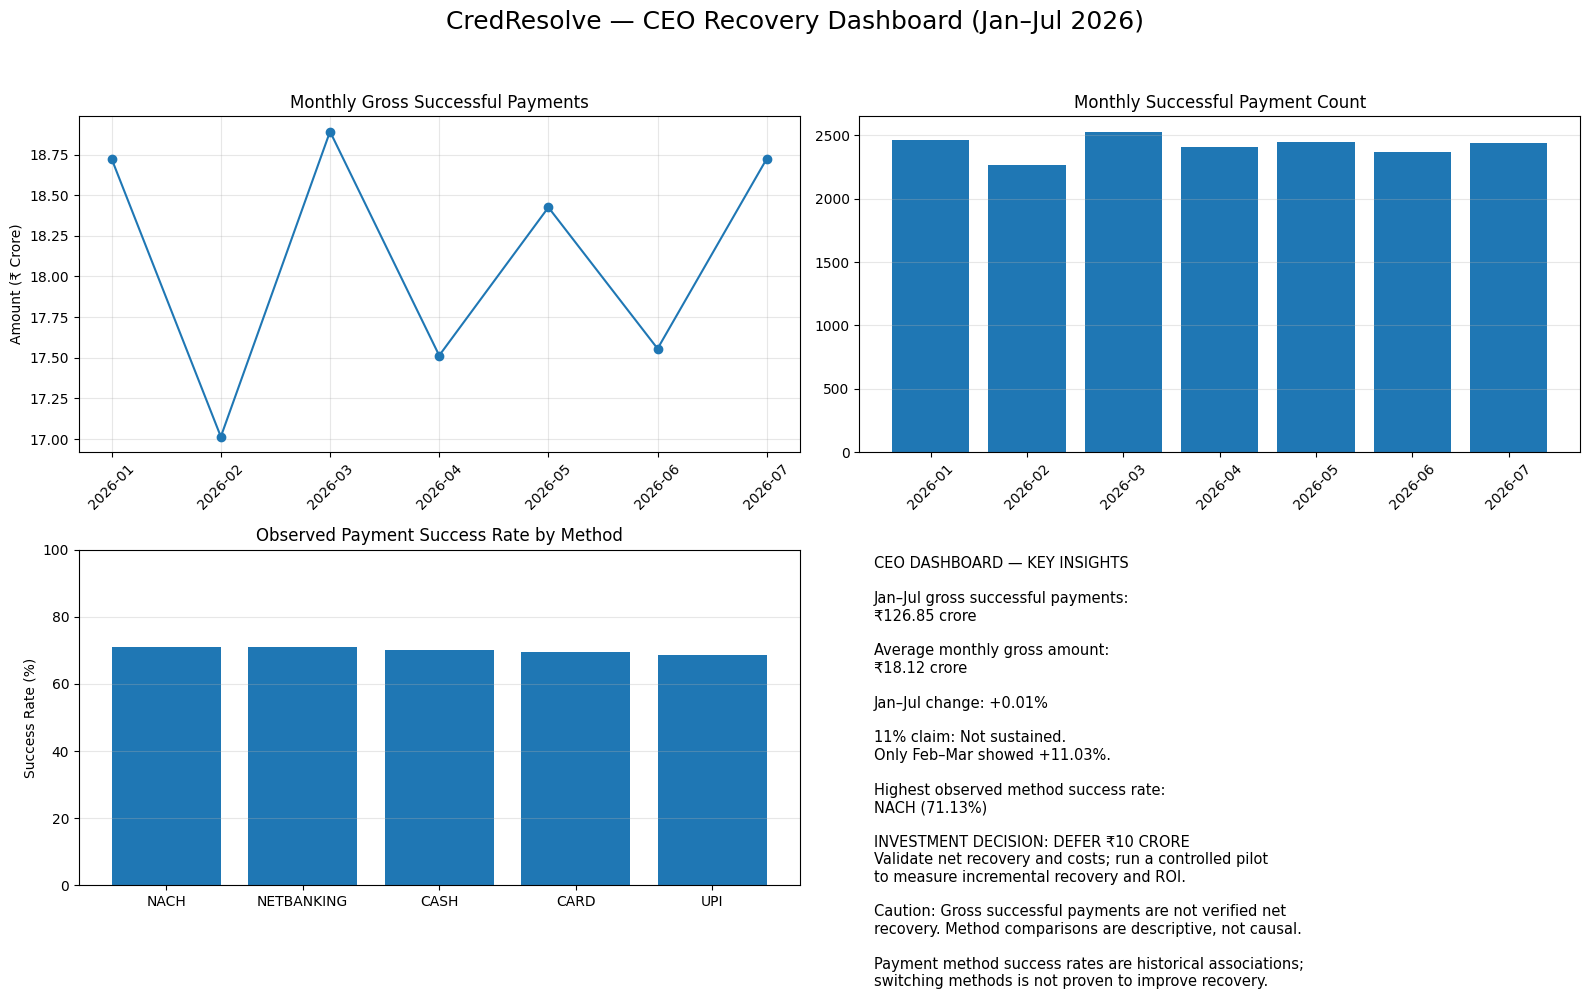

Updated dashboard: C:\Users\GOPICHAND\Desktop\CredResolve\outputs\ceo_dashboard.png


In [113]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Load saved analysis outputs
monthly = pd.read_csv(output_dir / "monthly_recovery_analysis.csv")
methods = pd.read_csv(output_dir / "payment_method_analysis.csv")

# Use complete months only: January–July 2026
monthly = monthly[monthly["month"] <= "2026-07"].copy()

# Verified calculations
total_gross_crore = monthly["gross_successful_amount"].sum() / 10_000_000
average_monthly_crore = monthly["amount_crore"].mean()
jan_jul_change = (
    monthly["gross_successful_amount"].iloc[-1]
    / monthly["gross_successful_amount"].iloc[0] - 1
) * 100

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle(
    "CredResolve — CEO Recovery Dashboard (Jan–Jul 2026)",
    fontsize=18,
    y=0.98
)

# 1. Monthly gross successful payments
axes[0, 0].plot(
    monthly["month"],
    monthly["amount_crore"],
    marker="o"
)
axes[0, 0].set_title("Monthly Gross Successful Payments")
axes[0, 0].set_ylabel("Amount (₹ Crore)")
axes[0, 0].tick_params(axis="x", rotation=45)
axes[0, 0].grid(True, alpha=0.3)

# 2. Monthly successful payment count
axes[0, 1].bar(
    monthly["month"],
    monthly["successful_payment_count"]
)
axes[0, 1].set_title("Monthly Successful Payment Count")
axes[0, 1].tick_params(axis="x", rotation=45)
axes[0, 1].grid(axis="y", alpha=0.3)

# 3. Payment method success rates
methods = methods.sort_values("success_rate_pct", ascending=False)
axes[1, 0].bar(
    methods["payment_method"],
    methods["success_rate_pct"]
)
axes[1, 0].set_title("Observed Payment Success Rate by Method")
axes[1, 0].set_ylabel("Success Rate (%)")
axes[1, 0].set_ylim(0, 100)
axes[1, 0].grid(axis="y", alpha=0.3)

# 4. CEO insights and investment recommendation
axes[1, 1].axis("off")

insights = (
    "CEO DASHBOARD — KEY INSIGHTS\n\n"
    f"Jan–Jul gross successful payments:\n₹{total_gross_crore:.2f} crore\n\n"
    f"Average monthly gross amount:\n₹{average_monthly_crore:.2f} crore\n\n"
    f"Jan–Jul change: {jan_jul_change:+.2f}%\n\n"
    "11% claim: Not sustained.\nOnly Feb–Mar showed +11.03%.\n\n"
    "Highest observed method success rate:\n"
    f"{methods.iloc[0]['payment_method']} "
    f"({methods.iloc[0]['success_rate_pct']:.2f}%)\n\n"
    "INVESTMENT DECISION: DEFER ₹10 CRORE\n"
    "Validate net recovery and costs; run a controlled pilot\n"
    "to measure incremental recovery and ROI.\n\n"
    "Caution: Gross successful payments are not verified net\n"
    "recovery. Method comparisons are descriptive, not causal.\n\n"
    "Payment method success rates are historical associations;\n"
    "switching methods is not proven to improve recovery."
)

axes[1, 1].text(
    0.02, 0.98, insights,
    transform=axes[1, 1].transAxes,
    fontsize=10.5,
    va="top",
    wrap=True
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

dashboard_path = output_dir / "ceo_dashboard.png"
plt.savefig(dashboard_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Updated dashboard:", dashboard_path)